# Brent forecasting with MS-AR and MS-ARX

This notebook forecasts Brent futures prices with MS-AR and MS-ARX.
It includes estimation, backtesting, numerical checks, tables and plots.

## tl;dr

The saved run selected zero mean weight for conservative MS-AR, which gives the
no-change point forecast. MS-ARX selected a 756-return window, refits every 63
observations and a 0.25 mean weight. Its validation gain did not generalize across
longer exploratory test horizons. The source snapshot ends on **2026-10-09**.

**Evaluation status:** the follow-up reused the 2024+ test period inspected during
baseline development. Differences are descriptive, and this remains an
exploratory comparison.

## Setup and controls

Open from `OilForecastQF` and run cells from top to bottom. Install project
dependencies with `python -m pip install -r requirements.txt` if needed.
Statsmodels 0.15 is required for the saved model artifacts.

The default run loads the existing evidence and reruns independent checks.
Set `RERUN_MODEL = True` below to repeat baseline estimation followed by the
extended experiment. All generated results live in `Outputs/msar/`.


In [1]:
from dataclasses import asdict, dataclass, replace
from itertools import product
from pathlib import Path
from types import SimpleNamespace
import contextlib
import hashlib
import importlib.metadata
import io
import json
import platform
import time
import warnings

import matplotlib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import statsmodels
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.regime_switching.markov_autoregression import MarkovAutoregression
from statsmodels.tsa.statespace.sarimax import SARIMAX
from IPython.display import display, Markdown, Image

PROJECT_ROOT = next((p.resolve() for p in (Path.cwd(), Path.cwd() / "OilForecastQF")
                     if (p / "Data" / "raw" / "yahoo_daily.csv").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open msar.ipynb from OilForecastQF or the workspace root.")
RERUN_MODEL = False
RUN_CHECKS = True
VERIFY_SAVED_OUTPUTS = True
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 180)


## Baseline implementation

Two-regime MS-AR, exact forecasts, simulations and AR/RW benchmarks.

In [2]:
BASELINE_COLORS = {"MS-AR": "#2367A3", "AR": "#C38728", "RW": "#555B63"}


@dataclass
class BaselineConfig:
    input_path: Path = PROJECT_ROOT / "Data" / "raw" / "yahoo_daily.csv"
    output_dir: Path = PROJECT_ROOT / "Outputs" / "msar" / "baseline"
    target: str = "brent_fut"
    window: int = 1260
    refit_every: int = 63
    horizons: tuple = (1, 5, 10, 20, 40, 60)
    validation_start: str = "2022-01-01"
    test_start: str = "2024-01-01"
    n_sim: int = 4000
    latest_n_sim: int = 50000
    seed: int = 5210


@dataclass(frozen=True)
class BaselineSpecification:
    order: int
    switching_ar: bool = False

    @property
    def name(self):
        return f"MS-AR({self.order})-{'switching' if self.switching_ar else 'shared'}-AR"

### Load and validate Brent prices

In [3]:
def load_prices(cfg: BaselineConfig) -> pd.Series:
    """Only observed, positive Brent prices; no forward-fill or interpolation."""
    raw = pd.read_csv(cfg.input_path, parse_dates=["date"])
    if raw["date"].isna().any() or raw["date"].duplicated().any():
        raise ValueError("Source has missing or duplicate dates; repair source first.")
    s = raw.set_index("date")[cfg.target].sort_index()
    if (s.dropna() <= 0).any() or not np.isfinite(s.dropna()).all():
        raise ValueError("Nonpositive/nonfinite prices cannot be logged.")
    s = s.dropna().astype(float)
    s.name = "Brent futures (USD/barrel)"
    if len(s) < cfg.window + max(cfg.horizons) + 250:
        raise ValueError("Not enough observed prices for this experiment.")
    return s

### Model construction and admissible fitting

In [4]:
def baseline_make_model(history, spec):
    return MarkovAutoregression(
        np.asarray(history, dtype=float), k_regimes=2, order=spec.order,
        trend="c", switching_trend=True, switching_ar=spec.switching_ar,
        switching_variance=True,
    )


def baseline_unpack(model, params):
    mu = np.array([params[model.parameters[s, "exog"]][0] for s in range(2)])
    phi = np.array([params[model.parameters[s, "autoregressive"]] for s in range(2)])
    variance = np.array([params[model.parameters[s, "variance"]][0] for s in range(2)])
    transition = model.regime_transition_matrix(params)[:, :, 0]
    return mu, phi, variance, transition


def baseline_mean_square_radius(phi, transition):
    """Spectral radius of the Markov jump companion second-moment operator."""
    p = phi.shape[1]
    companions = []
    for row in phi:
        a = np.zeros((p, p))
        a[0] = row
        if p > 1:
            a[1:, :-1] = np.eye(p - 1)
        companions.append(a)
    operator = np.block([
        [transition[j, i] * np.kron(companions[j], companions[j]) for i in range(2)]
        for j in range(2)
    ])
    return float(np.max(np.abs(np.linalg.eigvals(operator))))


def baseline_fit_ms(history, spec, seed, warm=None):
    """Select the highest-likelihood admissible fit using only this history."""
    model = baseline_make_model(history, spec)
    attempts, accepted = [], []
    starters = [("cold_search", None)]
    if warm is not None:
        starters.append(("warm", warm))
    else:
        starters.append(("second_search", None))
    for number, (kind, start) in enumerate(starters):
        try:
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")
                result = model.fit(
                    start_params=start, search_reps=5 if start is None else 0,
                    maxiter=300, disp=False, cov_type="none", rng=np.random.default_rng(seed + number),
                )
            mu, phi, variance, transition = baseline_unpack(model, result.params)
            occupancy = np.asarray(result.filtered_marginal_probabilities).mean(axis=0)
            radius = baseline_mean_square_radius(phi, transition)
            good = (
                bool(result.mle_retvals.get("converged", False))
                and np.isfinite(result.llf) and np.isfinite(result.params).all()
                and (variance > 1e-6).all() and occupancy.min() >= 0.01
                and np.diag(transition).min() > 0.001
                and np.diag(transition).max() < 0.99999 and radius < 0.999
            )
            attempts.append({"attempt": kind, "accepted": bool(good), "llf": float(result.llf),
                             "converged": bool(result.mle_retvals.get("converged", False)),
                             "occupancy_min": float(occupancy.min()), "second_moment_radius": radius,
                             "warnings": sorted(set(str(w.message) for w in caught))})
            if good:
                accepted.append(result)
        except Exception as exc:
            attempts.append({"attempt": kind, "accepted": False, "error": str(exc)})
    if not accepted:
        raise RuntimeError(f"No admissible fit for {spec.name}: {attempts}")
    best = max(accepted, key=lambda x: x.llf)
    return np.asarray(best.params), best, attempts

### Exact moments and predictive simulations

In [5]:
def baseline_exact_return_forecast(model, params, joint, history, horizon):
    """Exact conditional mean: propagate regime-weighted centered lag moments.

    joint axes are S_t, S_(t-1), ..., S_(t-p). Returns in percent.
    Let z_t=y_t-mu[S_t]. E[z_(t+1)|states]=sum phi[S_(t+1)]*z_lag.
    Conditioning weighted lag moments on S_t closes the linear recursion.
    """
    mu, phi, variance, transition = baseline_unpack(model, params)
    p = model.order
    probs = joint.sum(axis=tuple(range(1, joint.ndim)))
    indices = np.indices(joint.shape)
    last_y = np.asarray(history[-p:])[::-1]
    moments = np.zeros((2, p))
    for s in range(2):
        for lag in range(p):
            moments[s, lag] = np.sum(joint * (indices[0] == s) * (last_y[lag] - mu[indices[lag]]))
    daily = np.zeros(horizon)
    regime_prob = np.zeros((horizon, 2))
    for step in range(horizon):
        next_probs = transition @ probs
        mixed_moments = transition @ moments
        newest = np.sum(phi * mixed_moments, axis=1)
        daily[step] = np.dot(next_probs, mu) + newest.sum()
        moments = np.column_stack([newest, mixed_moments[:, :-1]])
        probs = next_probs
        regime_prob[step] = probs
    return np.cumsum(daily) / 100.0, regime_prob


def baseline_simulate_returns(model, params, joint, history, horizon, n_sim, seed):
    """Conditional paths sampled from the full filtered joint regime posterior."""
    mu, phi, variance, transition = baseline_unpack(model, params)
    rng = np.random.default_rng(seed)
    flat = np.maximum(joint.ravel(), 0)
    flat /= flat.sum()
    draw = rng.choice(flat.size, n_sim, p=flat)
    states = np.column_stack(np.unravel_index(draw, joint.shape))
    p = model.order
    past_states = states[:, :p].copy()
    past_returns = np.tile(np.asarray(history[-p:])[::-1], (n_sim, 1))
    cumulative = np.zeros((n_sim, horizon))
    total = np.zeros(n_sim)
    for step in range(horizon):
        # statsmodels transition matrix columns = previous regime, rows = next regime.
        new_state = (rng.random(n_sim) >= transition[0, past_states[:, 0]]).astype(int)
        expectation = mu[new_state] + np.sum(
            phi[new_state] * (past_returns - mu[past_states]), axis=1)
        y = expectation + np.sqrt(variance[new_state]) * rng.standard_normal(n_sim)
        total += y / 100.0
        cumulative[:, step] = total
        past_returns = np.column_stack([y, past_returns[:, :-1]])
        past_states = np.column_stack([new_state, past_states[:, :-1]])
    if not np.isfinite(cumulative).all() or np.max(np.abs(cumulative)) > 20:
        raise RuntimeError("Explosive/nonfinite simulations; no paths were trimmed.")
    return cumulative


def baseline_ordinary_ar_forecast(history, order, horizon):
    result = AutoReg(np.asarray(history), lags=order, trend="c").fit()
    forecast = np.asarray(result.predict(start=len(history), end=len(history) + horizon - 1))
    return np.cumsum(forecast) / 100, result


def baseline_origin_indices(prices, start, end=None):
    keep = prices.index >= pd.Timestamp(start)
    if end is not None:
        keep &= prices.index < pd.Timestamp(end)
    return np.flatnonzero(keep)

### Rolling estimation and forecast scoring

In [6]:
def baseline_rolling_forecasts(prices, spec, cfg, origins, phase, with_intervals=False):
    returns = np.log(prices).diff().to_numpy() * 100
    rows, regimes, fit_log = [], [], []
    params, last_fit = None, None
    max_h = max(cfg.horizons)
    for number, i in enumerate(origins):
        lo = max(1, i - cfg.window + 1)
        history = returns[lo:i + 1]
        if len(history) < cfg.window:
            raise ValueError("Origins require a complete estimation window.")
        if params is None or i - last_fit >= cfg.refit_every:
            params, fitted, attempts = baseline_fit_ms(history, spec, cfg.seed + int(i), warm=params)
            last_fit = i
            _, ar_fit = baseline_ordinary_ar_forecast(history, spec.order, max_h)
            ar_params = ar_fit.params
            fit_log.append({"phase": phase, "specification": spec.name,
                            "fit_date": str(prices.index[i].date()), "window_start": str(prices.index[lo].date()),
                            "observations": len(history), "llf": float(fitted.llf),
                            "aic": float(fitted.aic), "bic": float(fitted.bic), "attempts": attempts})
            print(f"[{phase}] {spec.name}: refit {prices.index[i].date()} ({number + 1}/{len(origins)})", flush=True)
        model = baseline_make_model(history, spec)
        filtered = model.filter(params, return_raw=True)
        joint = np.asarray(filtered.filtered_joint_probabilities[..., -1])
        means, regime_path = baseline_exact_return_forecast(model, params, joint, history, max_h)
        mu, phi, variance, transition = baseline_unpack(model, params)
        high_state = int(np.argmax(variance))
        marginal = joint.sum(axis=tuple(range(1, joint.ndim)))
        regimes.append({"date": prices.index[i], "phase": phase,
                        "high_vol_probability": float(marginal[high_state]),
                        "daily_return_pct": float(returns[i]), "price": float(prices.iloc[i]),
                        "fit_date": prices.index[last_fit]})
        simulations = None
        if with_intervals:
            simulations = baseline_simulate_returns(model, params, joint, history, max_h, cfg.n_sim, cfg.seed + i)
        # Refit AR parameters on the same dates as MS-AR, then recursively forecast from today's lags.
        ar_hist = list(history[-spec.order:])
        ar_steps = []
        for step in range(max_h):
            value = ar_params[0] + np.dot(ar_params[1:], ar_hist[-spec.order:][::-1])
            ar_steps.append(value)
            ar_hist.append(value)
        ar_means = np.cumsum(ar_steps) / 100
        for h in cfg.horizons:
            actual_return = float(np.log(prices.iloc[i + h] / prices.iloc[i]))
            base = {"phase": phase, "origin_date": prices.index[i], "target_date": prices.index[i + h],
                    "horizon": h, "price_now": float(prices.iloc[i]),
                    "actual_return": actual_return, "actual_price": float(prices.iloc[i + h]),
                    "fit_date": prices.index[last_fit]}
            for name, forecast in (("MS-AR", means[h - 1]), ("AR", ar_means[h - 1]), ("RW", 0.0)):
                row = {**base, "model": name, "forecast_return": float(forecast),
                       "forecast_price": float(prices.iloc[i] * np.exp(forecast))}
                if name == "MS-AR" and simulations is not None:
                    quantiles = np.quantile(simulations[:, h - 1], [.025, .1, .9, .975])
                    row.update(dict(zip(["return_lo95", "return_lo80", "return_hi80", "return_hi95"], quantiles)))
                rows.append(row)
    return pd.DataFrame(rows), pd.DataFrame(regimes), fit_log


def evaluate(forecasts):
    rows = []
    for (model, h), g in forecasts.groupby(["model", "horizon"]):
        error = g.forecast_return - g.actual_return
        price_error = g.forecast_price - g.actual_price
        predicted_direction = np.sign(g.forecast_return)
        actual_direction = np.sign(g.actual_return)
        active = predicted_direction != 0
        row = {"model": model, "horizon": int(h), "n_forecasts": len(g),
               "return_mae_pct": float(np.abs(error).mean() * 100),
               "return_rmse_pct": float(np.sqrt(np.mean(error ** 2)) * 100),
               "price_mae_usd": float(np.abs(price_error).mean()),
               "price_rmse_usd": float(np.sqrt(np.mean(price_error ** 2))),
               "directional_accuracy_pct": float(np.mean(predicted_direction[active] == actual_direction[active]) * 100) if active.any() else np.nan,
               "directional_prediction_share_pct": float(active.mean() * 100)}
        if "return_lo80" in g and g.return_lo80.notna().all():
            row["coverage80_pct"] = float(((g.actual_return >= g.return_lo80) & (g.actual_return <= g.return_hi80)).mean() * 100)
            row["coverage95_pct"] = float(((g.actual_return >= g.return_lo95) & (g.actual_return <= g.return_hi95)).mean() * 100)
        rows.append(row)
    metrics = pd.DataFrame(rows)
    rw = metrics[metrics.model == "RW"].set_index("horizon")
    metrics["rmse_improvement_vs_rw_pct"] = [
        (1 - r.return_rmse_pct / rw.loc[r.horizon, "return_rmse_pct"]) * 100 for r in metrics.itertuples()]
    return metrics.sort_values(["horizon", "model"]).reset_index(drop=True)

### Current forecasts and numerical verification

In [7]:
def baseline_latest_forecast(prices, spec, cfg):
    history = np.log(prices).diff().dropna().iloc[-cfg.window:].to_numpy() * 100
    params, result, attempts = baseline_fit_ms(history, spec, cfg.seed + 99999)
    model = result.model
    joint = np.asarray(result.filtered_joint_probabilities[..., -1])
    means, regime_path = baseline_exact_return_forecast(model, params, joint, history, max(cfg.horizons))
    simulations = baseline_simulate_returns(model, params, joint, history, max(cfg.horizons), cfg.latest_n_sim, cfg.seed + 99998)
    mu, phi, variance, transition = baseline_unpack(model, params)
    order = np.argsort(variance)
    marginal = joint.sum(axis=tuple(range(1, joint.ndim)))
    latest_rows = []
    for h in range(1, max(cfg.horizons) + 1):
        r = simulations[:, h - 1]
        p = prices.iloc[-1] * np.exp(r)
        quantiles = np.quantile(p, [.025, .1, .5, .9, .975])
        latest_rows.append({"asof_date": prices.index[-1], "horizon": h,
                           "indicative_business_date": prices.index[-1] + pd.offsets.BDay(h),
                           "price_now": float(prices.iloc[-1]), "forecast_return": float(means[h - 1]),
                           "forecast_price": float(prices.iloc[-1] * np.exp(means[h - 1])),
                           "expected_price": float(p.mean()), "expected_price_mc_se": float(p.std(ddof=1) / np.sqrt(len(p))),
                           "price_lo95": float(quantiles[0]), "price_lo80": float(quantiles[1]),
                           "price_median": float(quantiles[2]), "price_hi80": float(quantiles[3]),
                           "price_hi95": float(quantiles[4]), "high_vol_probability": float(regime_path[h - 1, order[-1]])})
    parameters = []
    transitions = []
    for rank, state in enumerate(order):
        label = "low_vol" if rank == 0 else "high_vol"
        parameters.append({"regime": label, "state_id": int(state), "mean_parameter_pct": float(mu[state]),
                           "shock_sd_pct": float(np.sqrt(variance[state])),
                           "current_probability": float(marginal[state]),
                           "expected_duration_trading_days": float(1 / (1 - transition[state, state])),
                           **{f"ar_lag{j + 1}": float(value) for j, value in enumerate(phi[state])}})
        for next_rank, next_state in enumerate(order):
            transitions.append({"from_regime": label, "to_regime": "low_vol" if next_rank == 0 else "high_vol",
                                "probability": float(transition[next_state, state])})
    diagnostic = {"latest_fit_attempts": attempts, "latest_llf": float(result.llf),
                  "second_moment_radius": baseline_mean_square_radius(phi, transition),
                  "latest_high_vol_probability": float(marginal[order[-1]]),
                  "latest_parameters": params.tolist()}
    return pd.DataFrame(latest_rows), pd.DataFrame(parameters), pd.DataFrame(transitions), diagnostic, result


def baseline_verify_forecaster(result, history, seed):
    """Independent enumeration of one-step mean and MC agreement at 1/5/60 steps."""
    model, params = result.model, np.asarray(result.params)
    joint = np.asarray(result.filtered_joint_probabilities[..., -1])
    mu, phi, variance, transition = baseline_unpack(model, params)
    exact, _ = baseline_exact_return_forecast(model, params, joint, history, 60)
    enumerated = 0.0
    lags = np.asarray(history[-model.order:])[::-1]
    for states in np.ndindex(joint.shape):
        for next_state in range(2):
            conditional = mu[next_state] + sum(phi[next_state, j] * (lags[j] - mu[states[j]]) for j in range(model.order))
            enumerated += joint[states] * transition[next_state, states[0]] * conditional / 100
    if not np.isclose(enumerated, exact[0], atol=1e-12):
        raise AssertionError("One-step enumeration and moment recursion disagree.")
    sims = baseline_simulate_returns(model, params, joint, history, 60, 100000, seed)
    checks = []
    for h in (1, 5, 60):
        mc_mean = float(sims[:, h - 1].mean())
        mc_se = float(sims[:, h - 1].std(ddof=1) / np.sqrt(len(sims)))
        z = abs(mc_mean - exact[h - 1]) / mc_se
        if z > 5:
            raise AssertionError(f"Exact expectation and simulation disagree at h={h}: z={z}")
        checks.append({"horizon": h, "exact_mean_log_return": float(exact[h - 1]),
                       "simulation_mean": mc_mean, "simulation_mc_se": mc_se, "absolute_z": float(z)})
    return {"one_step_enumeration_passed": True, "simulation_mean_checks": checks}

### Shared plotting style and baseline figures

In [8]:
def set_style():
    plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                         "axes.spines.top": False, "axes.spines.right": False,
                         "axes.edgecolor": "#757B82", "axes.labelcolor": "#24292F",
                         "text.color": "#24292F", "axes.titlesize": 14, "figure.facecolor": "white",
                         "savefig.facecolor": "white", "axes.grid": True,
                         "grid.color": "#E6E8EB", "grid.linewidth": .6})


def baseline_make_figures(prices, regimes, metrics, latest_path, cfg):
    set_style()
    out = cfg.output_dir / "figures"
    out.mkdir(parents=True, exist_ok=True)
    fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True, layout="constrained")
    display = prices.loc[pd.Timestamp(cfg.validation_start):]
    axes[0].plot(display.index, display, color=BASELINE_COLORS["MS-AR"], lw=1.2)
    axes[0].set(ylabel="USD/barrel", title="Brent futures and real-time MS-AR regime probabilities")
    r = np.log(display).diff() * 100
    axes[1].plot(r.index, r, color="#626970", lw=.7)
    axes[1].set(ylabel="Daily log return (%)")
    # Validation probabilities at its purged tail were not forecast origins. Show a true gap.
    for phase, g in regimes.groupby("phase"):
        axes[2].plot(g.date, g.high_vol_probability * 100, color=BASELINE_COLORS["MS-AR"], lw=1.2)
    axes[2].set(ylabel="High-vol probability (%)", ylim=(0, 100))
    for ax in axes:
        ax.axvline(pd.Timestamp(cfg.test_start), color="#C38728", linestyle="--", lw=1)
    axes[0].plot([], [], color="#C38728", linestyle="--", lw=1, label="Held-out test starts")
    axes[0].legend(frameon=False, fontsize=10, loc="upper right")
    year_ticks = [pd.Timestamp(f"{year}-01-01") for year in range(display.index[0].year + 1, display.index[-1].year + 1)]
    ticks = [display.index[0], *year_ticks, display.index[-1]]
    axes[2].set_xticks(ticks)
    axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    axes[2].set_xlabel("Probabilities shown only at scored forecast origins; gaps mark excluded dates", fontsize=10)
    axes[2].set_xlim(display.index[0], display.index[-1])
    fig.savefig(out / "regimes.png", dpi=160)
    plt.close(fig)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), layout="constrained")
    x = np.arange(len(cfg.horizons))
    for n, name in enumerate(("RW", "AR", "MS-AR")):
        g = metrics[metrics.model == name].set_index("horizon").loc[list(cfg.horizons)]
        axes[0].bar(x + (n - 1) * .25, g.return_rmse_pct, width=.23, color=BASELINE_COLORS[name], label=name,
                    hatch="//" if name == "AR" else None)
        if name != "RW":
            axes[1].plot(x, g.directional_accuracy_pct, marker="o" if name == "MS-AR" else "s",
                         color=BASELINE_COLORS[name], linestyle="-" if name == "MS-AR" else "--", label=name)
    axes[0].set(title="Test error on cumulative log returns", ylabel="RMSE (percentage points)",
                xticks=x, xticklabels=list(cfg.horizons), xlabel="Trading-day horizon")
    axes[1].set(title="Test directional accuracy", ylabel="Correct direction (%)", ylim=(0, 100),
                xticks=x, xticklabels=list(cfg.horizons), xlabel="Trading-day horizon")
    axes[1].axhline(50, color="#555B63", ls=":", lw=1, label="50% reference")
    for ax in axes:
        ax.legend(frameon=False, fontsize=10)
    fig.savefig(out / "accuracy.png", dpi=160)
    plt.close(fig)
    fig, ax = plt.subplots(figsize=(11, 5), layout="constrained")
    recent = prices.iloc[-100:]
    dates = pd.to_datetime(latest_path.indicative_business_date)
    ax.plot(recent.index, recent, color="#555B63", lw=1.4, label="Observed Brent futures")
    ax.fill_between(dates, latest_path.price_lo95, latest_path.price_hi95, color=BASELINE_COLORS["MS-AR"], alpha=.10, label="95% conditional prediction interval")
    ax.fill_between(dates, latest_path.price_lo80, latest_path.price_hi80, color=BASELINE_COLORS["MS-AR"], alpha=.22, label="80% conditional prediction interval")
    ax.plot(dates, latest_path.forecast_price, color=BASELINE_COLORS["MS-AR"], lw=1.8, label="Price implied by expected log return")
    ax.axvline(prices.index[-1], color="#C38728", ls="--", lw=1)
    ax.set(title=f"Brent MS-AR forecast as of {prices.index[-1].date()}", ylabel="USD/barrel",
           xlabel="Future dates are indicative weekdays; horizons are trading observations")
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=5, maxticks=8))
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
    ax.set_xticks([recent.index[0], recent.index[len(recent) // 2], prices.index[-1],
                  dates.iloc[len(dates) // 2], dates.iloc[-1]])
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b %Y"))
    ax.legend(frameon=False, fontsize=9, loc="upper left")
    fig.savefig(out / "latest_forecast.png", dpi=160)
    plt.close(fig)


def json_write(path, value):
    def fallback(item):
        if isinstance(item, Path):
            return str(item)
        if isinstance(item, np.generic):
            return item.item()
        if isinstance(item, pd.Timestamp):
            return str(item.date())
        raise TypeError(type(item))
    path.write_text(json.dumps(value, indent=2, default=fallback, allow_nan=False), encoding="utf-8")

### Baseline experiment runner

In [9]:
def baseline_run_project(cfg=None):
    cfg = cfg or BaselineConfig()
    began = time.time()
    cfg.output_dir.mkdir(parents=True, exist_ok=True)
    prices = load_prices(cfg)
    raw = pd.read_csv(cfg.input_path)
    nonmissing = raw[cfg.target].dropna()
    quality = {
        "source_path": str(cfg.input_path.resolve()),
        "source_sha256": hashlib.sha256(cfg.input_path.read_bytes()).hexdigest(),
        "target": cfg.target, "ticker": "BZ=F", "source_provider": "Yahoo Finance, according to local download script",
        "series_definition": "Unadjusted front-month Brent futures Close, USD/barrel; contract-roll jumps retained",
        "observed_prices": len(prices), "observed_daily_returns": len(prices) - 1,
        "first_date": str(prices.index[0].date()), "last_date": str(prices.index[-1].date()),
        "duplicate_dates": int(raw.date.duplicated().sum()), "nonpositive_prices": int((nonmissing <= 0).sum()),
        "missing_rows_in_union_calendar": int(raw[cfg.target].isna().sum()),
        "internal_missing_rows_in_union_calendar": int(raw.set_index("date").loc[str(prices.index[0].date()):str(prices.index[-1].date()), cfg.target].isna().sum()),
        "maximum_observed_calendar_gap_days": int(prices.index.to_series().diff().dt.days.max()),
        "missing_treatment": "Drop absent Brent observations, no filling; holidays and genuine missing quotes not independently distinguished",
        "no_fresh_download": True,
    }
    json_write(cfg.output_dir / "data_quality.json", quality)
    prices.to_frame("brent_fut").rename_axis("date").to_csv(cfg.output_dir / "brent_prices.csv")
    maximum = max(cfg.horizons)
    validation = baseline_origin_indices(prices, cfg.validation_start, cfg.test_start)
    validation = np.array([i for i in validation if i + maximum < len(prices)
                           and prices.index[i + maximum] < pd.Timestamp(cfg.test_start)])
    test = baseline_origin_indices(prices, cfg.test_start)
    test = test[test + maximum < len(prices)]
    if len(validation) < 100 or len(test) < 100:
        raise ValueError("Validation/test windows too small for configured dates.")
    print(f"Data {quality['first_date']}..{quality['last_date']}: {len(prices)} prices. "
          f"Validation origins {len(validation)}; test origins {len(test)}.", flush=True)
    candidates = [BaselineSpecification(p, switch) for p in (1, 2) for switch in (False, True)]
    scores, fit_logs, cached = [], [], {}
    for spec in candidates:
        forecasts, regimes, log = baseline_rolling_forecasts(prices, spec, cfg, validation, "validation")
        metric = evaluate(forecasts)
        ms = metric[metric.model == "MS-AR"].set_index("horizon")
        rw = metric[metric.model == "RW"].set_index("horizon")
        ratios = ms.return_rmse_pct / rw.return_rmse_pct
        score = float(ratios.mean())
        scores.append({"specification": spec.name, "order": spec.order, "switching_ar": spec.switching_ar,
                       "mean_rmse_ratio_vs_rw": score, "mean_improvement_vs_rw_pct": (1 - score) * 100,
                       "n_origins": len(validation),
                       **{f"rmse_ratio_h{h}": float(ratios.loc[h]) for h in cfg.horizons}})
        fit_logs.extend(log)
        cached[spec.name] = (forecasts, regimes, metric)
        print(f"Validation score {spec.name}: {score:.5f} (lower is better)", flush=True)
    score_table = pd.DataFrame(scores).sort_values("mean_rmse_ratio_vs_rw").reset_index(drop=True)
    score_table.to_csv(cfg.output_dir / "validation_scores.csv", index=False)
    winner = score_table.iloc[0]
    selected = BaselineSpecification(int(winner.order), bool(winner.switching_ar))
    val_fc, val_regimes, val_metrics = cached[selected.name]
    val_fc.to_csv(cfg.output_dir / "validation_forecasts.csv", index=False)
    val_metrics.to_csv(cfg.output_dir / "validation_metrics.csv", index=False)
    print(f"Locked specification: {selected.name}", flush=True)
    forecasts, regimes, log = baseline_rolling_forecasts(prices, selected, cfg, test, "test", with_intervals=True)
    fit_logs.extend(log)
    metrics = evaluate(forecasts)
    forecasts.to_csv(cfg.output_dir / "backtest_forecasts.csv", index=False)
    metrics.to_csv(cfg.output_dir / "metrics.csv", index=False)
    # Market-condition splits use lagged, observable 20-day volatility and a pre-validation threshold.
    realized_vol = np.log(prices).diff().rolling(20).std() * 100
    threshold = float(realized_vol.loc[realized_vol.index < pd.Timestamp(cfg.validation_start)].median())
    forecast_regimes = forecasts.copy()
    forecast_regimes["condition"] = np.where(forecast_regimes.origin_date.map(realized_vol) > threshold, "higher_vol", "lower_vol")
    by_condition = []
    for condition, g in forecast_regimes.groupby("condition"):
        m = evaluate(g)
        m["condition"] = condition
        by_condition.append(m)
    pd.concat(by_condition).to_csv(cfg.output_dir / "metrics_by_condition.csv", index=False)
    by_year = []
    for year, g in forecasts.groupby(forecasts.origin_date.dt.year):
        m = evaluate(g)
        m["origin_year"] = year
        by_year.append(m)
    pd.concat(by_year).to_csv(cfg.output_dir / "metrics_by_year.csv", index=False)
    latest_path, parameters, transitions, diagnostic, latest_result = baseline_latest_forecast(prices, selected, cfg)
    history = np.log(prices).diff().dropna().iloc[-cfg.window:].to_numpy() * 100
    verification = baseline_verify_forecaster(latest_result, history, cfg.seed + 88888)
    latest_path.to_csv(cfg.output_dir / "latest_forecast_path.csv", index=False)
    latest_path[latest_path.horizon.isin(cfg.horizons)].to_csv(cfg.output_dir / "latest_forecasts.csv", index=False)
    parameters.to_csv(cfg.output_dir / "regime_parameters.csv", index=False)
    transitions.to_csv(cfg.output_dir / "transitions.csv", index=False)
    all_regimes = pd.concat([val_regimes, regimes], ignore_index=True)
    # Include filtered tail probabilities to latest data using the final historical fit;
    # keep this display tail separate from scored backtest forecasts.
    latest_filter = np.asarray(latest_result.filtered_marginal_probabilities)
    latest_dates = prices.index[-len(history):][selected.order:]
    pd.DataFrame({"date": latest_dates, "high_vol_probability": latest_filter[:, int(parameters.iloc[1].state_id)]}).to_csv(cfg.output_dir / "latest_window_regimes.csv", index=False)
    all_regimes.to_csv(cfg.output_dir / "regime_probabilities.csv", index=False)
    json_write(cfg.output_dir / "fit_log.json", fit_logs)
    json_write(cfg.output_dir / "verification.json", verification)
    baseline_make_figures(prices, all_regimes, metrics, latest_path, cfg)
    summary = {
        "selected_specification": selected.name, "selected_order": selected.order,
        "switching_ar": selected.switching_ar, "config": asdict(cfg), "data": quality,
        "validation_first_origin": str(prices.index[validation[0]].date()),
        "validation_last_origin": str(prices.index[validation[-1]].date()),
        "validation_last_target": str(prices.index[validation[-1] + maximum].date()),
        "test_first_origin": str(prices.index[test[0]].date()),
        "test_last_origin": str(prices.index[test[-1]].date()),
        "test_last_target": str(prices.index[test[-1] + maximum].date()),
        "n_validation_origins": len(validation), "n_test_origins": len(test),
        "validation_score": float(winner.mean_rmse_ratio_vs_rw),
        "selection_rule": "Lowest equal-weight mean of horizon-specific cumulative-return RMSE ratios to RW on purged validation origins",
        "refit_rule": f"Fixed {cfg.window}-return rolling estimation window, parameters refitted every {cfg.refit_every} observed Brent trading days; state filtered daily",
        "latest_asof": str(prices.index[-1].date()), "latest_price": float(prices.iloc[-1]),
        "volatility_split_threshold_pct": threshold,
        "interval_definition": "Conditional 80/95% predictive intervals from Gaussian MS-AR paths; exclude parameter/model uncertainty",
        "price_point_definition": "P_t * exp(E[sum future log returns]); distinct from expected arithmetic price and simulated median",
        "return_units": "CSV forecast_return/actual_return decimal cumulative log return; metrics percentage points; internal daily returns percent",
        "benchmark_definitions": "RW: zero cumulative return/no price change. AR: same lag order, estimation window/refit origins as selected MS-AR",
        "live_update_rule": "Rerun the baseline estimation cell in msar.ipynb after local source CSV is updated; this notebook does not download data or schedule jobs",
        "overlap_caution": "Daily horizon errors overlap; descriptive differences, no significance claim",
        "source_caution": "Unadjusted front-month contract rolls retained; results concern this local extract, not an independently verified spot series",
        "n_fit_events": len(fit_logs), "verification": verification, **diagnostic,
        "versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                     "scipy": scipy.__version__, "statsmodels": statsmodels.__version__, "matplotlib": matplotlib.__version__},
        "elapsed_seconds": round(time.time() - began, 2),
    }
    json_write(cfg.output_dir / "run_summary.json", summary)
    print(metrics.to_string(index=False), flush=True)
    print(f"Finished in {summary['elapsed_seconds']:.1f}s. Outputs: {cfg.output_dir}", flush=True)
    return summary

## Conservative MS-AR and MS-ARX implementation

Shared utilities above are reused; all follow-up logic is visible here.

In [10]:
FEATURES = ("wti_change_usd", "dxy_log_return_pct", "brent_wti_spread_usd")


MODEL_COLORS = {"RW": "#555B63", "V1 MS-AR": "#B18235", "V2 conservative": "#386F97",
                "V2 MS-ARX": "#986287", "ARX": "#737C3F"}


COMPUTATION_VERSION = "2.1"


@dataclass
class ExtendedConfig:
    input_path: Path = PROJECT_ROOT / "Data" / "raw" / "yahoo_daily.csv"
    output_dir: Path = PROJECT_ROOT / "Outputs" / "msar" / "extended"
    original_dir: Path = PROJECT_ROOT / "Outputs" / "msar" / "baseline"
    horizons: tuple = (1, 5, 10, 20, 40, 60)
    windows: tuple = (504, 756, 1260)
    refit_schedules: tuple = (21, 63)
    weights: tuple = (0.0, 0.25, 0.5, 1.0)
    validation_start: str = "2022-01-01"
    test_start: str = "2024-01-01"
    n_sim: int = 3000
    latest_n_sim: int = 50000
    seed: int = 5210


@dataclass(frozen=True)
class ExtendedSpecification:
    family: str  # conservative / msarx
    mean_mode: str  # switching / shared / zero
    window: int
    refit_every: int

    @property
    def name(self):
        return f"{self.family}-{self.mean_mode}-w{self.window}-r{self.refit_every}"

### Causal cross-market inputs and fitted scalers

In [11]:
def extended_prepare_data(cfg, *, prices=None, source=None):
    if prices is None:
        prices = load_prices(BaselineConfig(input_path=cfg.input_path))
    if source is None:
        source = pd.read_csv(cfg.input_path, parse_dates=["date"])
    source = source.set_index("date").sort_index()
    quoted = source[["wti_fut", "dxy"]].reindex(prices.index)
    filled = quoted.ffill(limit=3)  # past quotes only; never backward-fill
    if filled.isna().any().any() or (filled.dxy <= 0).any():
        raise ValueError("Missing cross-market quote beyond causal fill limit, or nonpositive DXY.")
    current = pd.DataFrame({
        "wti_change_usd": filled.wti_fut.diff(),
        "dxy_log_return_pct": np.log(filled.dxy).diff() * 100,
        "brent_wti_spread_usd": prices - filled.wti_fut,
    }, index=prices.index)
    inputs = current.shift(1)  # daily target at t uses only predictors dated t-1
    panel = pd.concat([prices.rename("brent_fut"), filled, current.add_prefix("current_"),
                       inputs.add_prefix("lagged_")], axis=1)
    quality = {
        "source_path": str(cfg.input_path.resolve()),
        "source_sha256": hashlib.sha256(cfg.input_path.read_bytes()).hexdigest(),
        "price_count": len(prices), "first_date": str(prices.index[0].date()),
        "last_date": str(prices.index[-1].date()), "source_tickers": {"brent_fut": "BZ=F", "wti_fut": "CL=F", "dxy": "DX-Y.NYB"},
        "source_definition": "Local Yahoo unadjusted front-month futures closes; contract-roll jumps retained",
        "causally_filled_quote_counts": {c: int((quoted[c].isna() & filled[c].notna()).sum()) for c in quoted},
        "causal_fill_limit_brent_observations": 3,
        "nonpositive_wti_quotes": int((filled.wti_fut <= 0).sum()),
        "feature_definition": {"wti_change_usd": "WTI close dollar change between available Brent observations",
                               "dxy_log_return_pct": "100*log(DXY_t/DXY_previous_Brent_observation)",
                               "brent_wti_spread_usd": "Brent futures close minus WTI futures close, USD/barrel"},
        "feature_availability": "Fit/filter X_t=current_features_(t-1); first future X_(t+1)=current_features_t",
        "scaling": "Fit-window means and SDs only; scaler fixed between refits",
        "missing_initial_feature_rows": int(inputs.isna().any(axis=1).sum()),
        "no_brent_interpolation": True, "no_fresh_download": True,
    }
    return prices, np.log(prices).diff().to_numpy() * 100, inputs, current, panel, quality


def extended_scaler_for(history_x):
    means = np.mean(history_x, axis=0)
    scales = np.std(history_x, axis=0, ddof=0)
    if not np.isfinite(history_x).all() or (scales <= 1e-8).any():
        raise ValueError("Nonfinite or constant training feature.")
    return {"means": means, "scales": scales}


def extended_standardized(raw, scaler):
    return (np.asarray(raw) - scaler["means"]) / scaler["scales"]


def extended_future_feature_path(origin_features, horizon, scaler):
    """A conditional frozen-input path, NOT a joint Brent/WTI price scenario."""
    raw = np.tile(np.asarray(origin_features, dtype=float), (horizon, 1))
    raw[1:, :2] = 0.0  # subsequent WTI dollar changes / DXY log returns assumed zero
    # The origin spread stays fixed as a predictor. It is not recomputed from future Brent.
    return extended_standardized(raw, scaler), raw

### Follow-up model construction and fitting

In [12]:
def extended_make_model(history, spec, x=None):
    if spec.mean_mode not in ("switching", "shared", "zero"):
        raise ValueError(spec.mean_mode)
    return MarkovAutoregression(
        np.asarray(history), k_regimes=2, order=1,
        trend="n" if spec.mean_mode == "zero" else "c",
        switching_trend=spec.mean_mode == "switching",
        switching_ar=False, switching_variance=True,
        exog=x if spec.family == "msarx" else None, switching_exog=False,
    )


def extended_unpack(model, params):
    intercept = np.zeros(2)
    beta = np.zeros((2, model.k_exog))
    for s in range(2):
        coefficients = np.asarray(params[model.parameters[s, "exog"]])
        if model.k_trend:
            intercept[s] = coefficients[0]
        beta[s] = coefficients[model.k_trend:]
    phi = np.array([params[model.parameters[s, "autoregressive"]][0] for s in range(2)])
    variance = np.array([params[model.parameters[s, "variance"]][0] for s in range(2)])
    transition = model.regime_transition_matrix(params)[:, :, 0]
    return intercept, beta, phi, variance, transition


def extended_fit_ms(history, spec, x, seed, warm=None):
    model = extended_make_model(history, spec, x)
    accepted, attempts = [], []
    starters = [None, warm] if warm is not None else [None, None]
    for n, start in enumerate(starters):
        try:
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")
                fit = model.fit(start_params=start, search_reps=4 if start is None else 0,
                                maxiter=350, disp=False, cov_type="none", rng=np.random.default_rng(seed + n))
            intercept, beta, phi, variance, transition = extended_unpack(model, fit.params)
            occupancy = np.asarray(fit.filtered_marginal_probabilities).mean(axis=0)
            valid = bool(fit.mle_retvals.get("converged", False)) and np.isfinite(fit.params).all() and np.isfinite(fit.llf)
            valid &= (variance > 1e-6).all() and occupancy.min() >= .01
            valid &= np.max(np.abs(phi)) < .999 and np.diag(transition).min() > .001 and np.diag(transition).max() < .99999
            attempts.append({"start": "cold" if start is None else "warm", "accepted": bool(valid),
                             "converged": bool(fit.mle_retvals.get("converged", False)),
                             "llf": float(fit.llf) if np.isfinite(fit.llf) else None,
                             "occupancy_min": float(occupancy.min()),
                             "warnings": sorted(set(str(w.message) for w in caught))})
            if valid:
                accepted.append(fit)
        except Exception as exc:
            attempts.append({"accepted": False, "error": str(exc)})
    if not accepted:
        raise RuntimeError(f"No admissible fit for {spec.name}: {attempts}")
    best = max(accepted, key=lambda fit: fit.llf)
    return np.asarray(best.params), best, attempts

### Conditional moments and predictive simulations

In [13]:
def extended_exact_forecast(model, params, probabilities, y_last, x_last, future_x, horizon):
    """Hamilton AR(1): y_t=a(S_t,X_t)+z_t, z_(t+1)=phi(S_(t+1))*z_t+eps."""
    intercept, beta, phi, variance, transition = extended_unpack(model, params)
    probabilities = np.asarray(probabilities, dtype=float).copy()
    a_last = intercept + beta @ x_last
    moments = probabilities * (y_last - a_last)
    daily, regimes = np.zeros(horizon), np.zeros((horizon, 2))
    for step in range(horizon):
        moments = phi * (transition @ moments)
        probabilities = transition @ probabilities
        a_next = intercept + beta @ future_x[step]
        daily[step] = probabilities @ a_next + moments.sum()
        regimes[step] = probabilities
    return np.cumsum(daily) / 100, regimes


def extended_simulate(model, params, probabilities, y_last, x_last, future_x, horizon, n_sim, seed):
    intercept, beta, phi, variance, transition = extended_unpack(model, params)
    rng = np.random.default_rng(seed)
    probabilities = np.maximum(np.asarray(probabilities), 0)
    probabilities = probabilities / probabilities.sum()
    state = rng.choice(2, n_sim, p=probabilities)
    centered = y_last - (intercept + beta @ x_last)[state]
    paths, total = np.zeros((n_sim, horizon)), np.zeros(n_sim)
    for step in range(horizon):
        state = (rng.random(n_sim) >= transition[0, state]).astype(int)
        centered = phi[state] * centered + np.sqrt(variance[state]) * rng.standard_normal(n_sim)
        a_next = intercept + beta @ future_x[step]
        total += (a_next[state] + centered) / 100
        paths[:, step] = total
    if not np.isfinite(paths).all() or np.max(np.abs(paths)) > 20:
        raise RuntimeError("Nonfinite/explosive simulation; no path trimming.")
    return paths


def extended_fitted_history(returns, inputs, i, spec):
    lo = i - spec.window + 1
    if lo < 2:
        raise ValueError("Insufficient complete feature/return history.")
    history = returns[lo:i + 1]
    raw_x = inputs.iloc[lo:i + 1].to_numpy()
    if not np.isfinite(history).all() or not np.isfinite(raw_x).all():
        raise ValueError("Missing fit-window data; Brent calendar was not compressed.")
    return history, raw_x, lo

### Rolling forecasts and ordinary ARX control

In [14]:
def extended_roll(prices, returns, inputs, current, spec, cfg, origins, phase, weight=1.0, intervals=False, arx_control=False):
    rows, state_rows, logs = [], [], []
    params, scaler, last_fit, arx_params = None, None, None, None
    max_h = max(cfg.horizons)
    for n, i in enumerate(origins):
        history, raw_x, lo = extended_fitted_history(returns, inputs, int(i), spec)
        if params is None or i - last_fit >= spec.refit_every:
            scaler = extended_scaler_for(raw_x) if spec.family == "msarx" else None
            x = extended_standardized(raw_x, scaler) if scaler is not None else None
            params, fitted, attempts = extended_fit_ms(history, spec, x, cfg.seed + int(i), warm=params)
            last_fit = int(i)
            if arx_control:
                with warnings.catch_warnings(record=True) as arx_warnings:
                    warnings.simplefilter("always")
                    arx_fit = SARIMAX(history, exog=x, order=(1, 0, 0), trend="c").fit(disp=False, maxiter=300)
                if not arx_fit.mle_retvals.get("converged", False) or not np.isfinite(arx_fit.params).all():
                    raise RuntimeError("Single-regime ARX control failed to converge.")
                arx_params = np.asarray(arx_fit.params)
            logs.append({"phase": phase, "path": spec.name, "fit_date": str(prices.index[i].date()),
                         "window_start": str(prices.index[lo].date()), "observations": len(history),
                         "attempts": attempts, "scaler_means": scaler["means"].tolist() if scaler else [],
                         "scaler_sd": scaler["scales"].tolist() if scaler else [],
                         "arx_control_converged": True if arx_control else None})
            print(f"[{phase}] {spec.name}: refit {prices.index[i].date()} ({n + 1}/{len(origins)})", flush=True)
        x = extended_standardized(raw_x, scaler) if scaler is not None else None
        if scaler is not None:
            future_x, _ = extended_future_feature_path(current.iloc[i].to_numpy(), max_h, scaler)
            last_x = x[-1]
        else:
            future_x = np.empty((max_h, 0))
            last_x = np.empty(0)
        model = extended_make_model(history, spec, x)
        filtered = model.filter(params, return_raw=True)
        probabilities = np.asarray(filtered.filtered_marginal_probabilities[:, -1])
        raw_means, future_regimes = extended_exact_forecast(model, params, probabilities, history[-1], last_x, future_x, max_h)
        means = weight * raw_means
        intercept, beta, phi, variance, transition = extended_unpack(model, params)
        high = int(np.argmax(variance))
        state_rows.append({"date": prices.index[i], "family": spec.family, "phase": phase,
                           "high_vol_probability": float(probabilities[high]), "fit_date": prices.index[last_fit]})
        paths = None
        if intervals:
            paths = extended_simulate(model, params, probabilities, history[-1], last_x, future_x, max_h, cfg.n_sim, cfg.seed + int(i))
            paths = paths + (weight - 1) * raw_means[None, :]  # mean adjustment, unshrunk noise
        control_means = None
        if arx_control:
            control = SARIMAX(history, exog=x, order=(1, 0, 0), trend="c").filter(arx_params)
            control_means = np.cumsum(np.asarray(control.forecast(steps=max_h, exog=future_x))) / 100
        for h in cfg.horizons:
            row = {"phase": phase, "origin_date": prices.index[i], "target_date": prices.index[i + h],
                   "horizon": h, "price_now": float(prices.iloc[i]),
                   "actual_return": float(np.log(prices.iloc[i + h] / prices.iloc[i])),
                   "actual_price": float(prices.iloc[i + h]), "fit_date": prices.index[last_fit],
                   "raw_forecast_return": float(raw_means[h - 1]), "forecast_return": float(means[h - 1]),
                   "forecast_price": float(prices.iloc[i] * np.exp(means[h - 1])),
                   "mean_weight": weight, "path": spec.name}
            if paths is not None:
                quantiles = np.quantile(paths[:, h - 1], [.025, .1, .9, .975])
                row.update(dict(zip(["return_lo95", "return_lo80", "return_hi80", "return_hi95"], quantiles)))
            if control_means is not None:
                row["arx_raw_forecast_return"] = float(control_means[h - 1])
                row["arx_forecast_return"] = float(weight * control_means[h - 1])
            rows.append(row)
    return pd.DataFrame(rows), pd.DataFrame(state_rows), logs

### Validation cache, mean weights and selection

In [15]:
def extended_cache_signature(cfg, quality, spec, origins):
    settings = {"version": COMPUTATION_VERSION, "spec": asdict(spec), "horizons": cfg.horizons,
                "seed": cfg.seed, "source_sha256": quality["source_sha256"],
                "origin_first": int(origins[0]), "origin_last": int(origins[-1]), "origin_count": len(origins)}
    return hashlib.sha256(json.dumps(settings, sort_keys=True).encode()).hexdigest()


def extended_validation_path(prices, returns, inputs, current, spec, cfg, origins, quality):
    cache = cfg.output_dir / "validation_paths"
    cache.mkdir(parents=True, exist_ok=True)
    csv_path, log_path = cache / f"{spec.name}.csv", cache / f"{spec.name}.json"
    fingerprint = extended_cache_signature(cfg, quality, spec, origins)
    if csv_path.exists() and log_path.exists():
        metadata = json.loads(log_path.read_text())
        if metadata.get("fingerprint") == fingerprint:
            print(f"[validation] reuse checked cache {spec.name}", flush=True)
            return pd.read_csv(csv_path, parse_dates=["origin_date", "target_date", "fit_date"]), metadata["fits"]
    forecasts, regimes, logs = extended_roll(prices, returns, inputs, current, spec, cfg, origins, "validation")
    forecasts.to_csv(csv_path, index=False)
    json_write(log_path, {"fingerprint": fingerprint, "fits": logs})
    return forecasts, logs


def extended_score_weights(forecasts, spec, cfg):
    actual = forecasts.pivot(index="origin_date", columns="horizon", values="actual_return").loc[:, list(cfg.horizons)].to_numpy()
    raw = forecasts.pivot(index="origin_date", columns="horizon", values="raw_forecast_return").loc[:, list(cfg.horizons)].to_numpy()
    rw_rmse = np.sqrt(np.mean(actual ** 2, axis=0))
    scores = []
    for weight in cfg.weights:
        ratios = np.sqrt(np.mean((raw * weight - actual) ** 2, axis=0)) / rw_rmse
        scores.append({**asdict(spec), "path": spec.name, "mean_weight": weight,
                       "validation_score": float(ratios.mean()), "validation_improvement_vs_rw_pct": float((1 - ratios.mean()) * 100),
                       "n_origins": len(actual), **{f"rmse_ratio_h{h}": float(ratios[k]) for k, h in enumerate(cfg.horizons)}})
    return scores


def extended_choose(scores, family):
    candidates = scores[scores.family == family].copy()
    best = candidates.validation_score.min()
    tied = candidates[np.abs(candidates.validation_score - best) <= 1e-10].copy()
    # Conservative predeclared tie rule: no-change first; longer window, slower refits, fewer mean parameters.
    tied["mean_complexity"] = tied.mean_mode.map({"zero": 0, "shared": 1, "switching": 2})
    winner = tied.sort_values(["mean_weight", "window", "refit_every", "mean_complexity"],
                             ascending=[True, False, False, True]).iloc[0]
    spec = ExtendedSpecification(family, str(winner.mean_mode), int(winner.window), int(winner.refit_every))
    return spec, float(winner.mean_weight), winner.drop(labels="mean_complexity").to_dict()

### Current forecast artifacts and checks

In [16]:
def extended_verify_forecast(model, params, probabilities, y_last, x_last, future_x, seed):
    exact, _ = extended_exact_forecast(model, params, probabilities, y_last, x_last, future_x, 60)
    intercept, beta, phi, variance, transition = extended_unpack(model, params)
    explicit = 0.0
    current_mean = intercept + beta @ x_last
    next_mean = intercept + beta @ future_x[0]
    for previous in range(2):
        for nxt in range(2):
            explicit += probabilities[previous] * transition[nxt, previous] * (
                next_mean[nxt] + phi[nxt] * (y_last - current_mean[previous])) / 100
    if not np.isclose(explicit, exact[0], atol=1e-12):
        raise AssertionError("ARX one-step independent enumeration failed.")
    paths = extended_simulate(model, params, probabilities, y_last, x_last, future_x, 60, 100000, seed)
    checks = []
    for h in (1, 5, 60):
        observed = float(paths[:, h - 1].mean())
        se = float(paths[:, h - 1].std(ddof=1) / np.sqrt(len(paths)))
        z = abs(observed - exact[h - 1]) / se
        if z > 5:
            raise AssertionError(f"Simulation/exact expectation discrepancy, h={h}, z={z}")
        checks.append({"horizon": h, "exact_mean": float(exact[h - 1]), "mc_mean": observed, "mc_se": se, "absolute_z": float(z)})
    return {"one_step_enumeration_passed": True, "simulation_checks": checks}


def extended_latest(prices, returns, inputs, current, spec, weight, cfg, name):
    i = len(prices) - 1
    history, raw_x, lo = extended_fitted_history(returns, inputs, i, spec)
    scaler = extended_scaler_for(raw_x) if spec.family == "msarx" else None
    x = extended_standardized(raw_x, scaler) if scaler else None
    params, fit, attempts = extended_fit_ms(history, spec, x, cfg.seed + 99999)
    model = fit.model
    probabilities = np.asarray(fit.filtered_marginal_probabilities[-1])
    if scaler:
        future_x, raw_future = extended_future_feature_path(current.iloc[i].to_numpy(), max(cfg.horizons), scaler)
        x_last = x[-1]
    else:
        future_x, raw_future, x_last = np.empty((max(cfg.horizons), 0)), np.empty((max(cfg.horizons), 0)), np.empty(0)
    raw_means, probabilities_path = extended_exact_forecast(model, params, probabilities, history[-1], x_last, future_x, max(cfg.horizons))
    paths = extended_simulate(model, params, probabilities, history[-1], x_last, future_x, max(cfg.horizons), cfg.latest_n_sim, cfg.seed + 99998)
    adjusted_paths = paths + (weight - 1) * raw_means[None, :]
    intercept, beta, phi, variance, transition = extended_unpack(model, params)
    order = np.argsort(variance)
    rows = []
    for h in range(1, max(cfg.horizons) + 1):
        return_draws = adjusted_paths[:, h - 1]
        price_draws = prices.iloc[-1] * np.exp(return_draws)
        q = np.quantile(price_draws, [.025, .1, .5, .9, .975])
        rows.append({"model": name, "asof_date": prices.index[-1], "horizon": h,
                     "indicative_business_date": prices.index[-1] + pd.offsets.BDay(h),
                     "price_now": float(prices.iloc[-1]), "mean_weight": weight,
                     "raw_forecast_return": float(raw_means[h - 1]), "forecast_return": float(weight * raw_means[h - 1]),
                     "forecast_price": float(prices.iloc[-1] * np.exp(weight * raw_means[h - 1])),
                     "expected_price": float(price_draws.mean()), "expected_price_mc_se": float(price_draws.std(ddof=1) / np.sqrt(len(price_draws))),
                     "price_lo95": float(q[0]), "price_lo80": float(q[1]), "price_median": float(q[2]),
                     "price_hi80": float(q[3]), "price_hi95": float(q[4]),
                     "high_vol_probability": float(probabilities_path[h - 1, order[-1]])})
    parameter_rows = []
    transition_rows = []
    for rank, s in enumerate(order):
        label = "low_vol" if rank == 0 else "high_vol"
        parameter_rows.append({"model": name, "regime": label, "state_id": int(s),
                               "intercept_pct": float(intercept[s]), "shock_sd_pct": float(np.sqrt(variance[s])),
                               "ar_lag1": float(phi[s]), "current_probability": float(probabilities[s]),
                               "expected_duration_sessions": float(1 / (1 - transition[s, s])),
                               **{f"beta_{feature}": float(beta[s, k]) for k, feature in enumerate(FEATURES) if beta.shape[1]}})
        for next_rank, nxt in enumerate(order):
            transition_rows.append({"model": name, "from_regime": label, "to_regime": "low_vol" if next_rank == 0 else "high_vol",
                                    "probability": float(transition[nxt, s])})
    proof = extended_verify_forecast(model, params, probabilities, history[-1], x_last, future_x, cfg.seed + 88888)
    artifact = {"model": name, "specification": asdict(spec), "mean_weight": weight,
                "params": params.tolist(), "train_start": str(prices.index[lo].date()),
                "train_end": str(prices.index[-1].date()), "scaler": {k: v.tolist() for k, v in scaler.items()} if scaler else None,
                "last_observed_X": x_last.tolist(), "future_raw_X": raw_future.tolist(), "future_standardized_X": future_x.tolist(),
                "current_regime_probabilities": probabilities.tolist(), "fit_attempts": attempts,
                "simulation_seed": cfg.seed + 99998, "simulation_paths": cfg.latest_n_sim,
                "verification": proof}
    return pd.DataFrame(rows), pd.DataFrame(parameter_rows), pd.DataFrame(transition_rows), artifact

### Follow-up diagnostic figures

In [17]:
def extended_chart_results(prices, metrics, states, latest_path, scores, cfg):
    set_style()
    out = cfg.output_dir / "figures"
    out.mkdir(exist_ok=True)
    names = list(MODEL_COLORS)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
    x = np.arange(len(cfg.horizons))
    for j, name in enumerate(names):
        data = metrics[metrics.model == name].set_index("horizon").loc[list(cfg.horizons)]
        axes[0].plot(x, data.return_rmse_pct, color=MODEL_COLORS[name], marker=["o", "s", "^", "D", "v"][j],
                     ls="--" if name in ("RW", "ARX") else "-", lw=1.5, label=name)
        axes[1].plot(x, data.rmse_improvement_vs_rw_pct, color=MODEL_COLORS[name], marker=["o", "s", "^", "D", "v"][j],
                     ls="--" if name in ("RW", "ARX") else "-", lw=1.5, label=name)
    axes[0].set(title="Exploratory cumulative-return errors", ylabel="RMSE (percentage points)", ylim=(0, None))
    axes[1].axhline(0, color="#555B63", lw=.8)
    axes[1].set(title="Difference relative to no-change", ylabel="RMSE improvement vs RW (%)")
    for ax in axes:
        ax.set(xticks=x, xticklabels=list(cfg.horizons), xlabel="Trading-observation horizon")
        ax.legend(frameon=False, fontsize=9)
    fig.savefig(out / "accuracy.png", dpi=160)
    plt.close(fig)
    fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True, layout="constrained")
    shown = prices.loc[cfg.test_start:]
    axes[0].plot(shown.index, shown, color="#555B63", lw=1.2)
    axes[0].set(title="Brent futures and real-time V2 regime probabilities", ylabel="USD/barrel")
    for family, label in (("conservative", "V2 conservative"), ("msarx", "V2 MS-ARX")):
        s = states[(states.family == family) & (states.phase == "exploratory_test")]
        axes[1].plot(s.date, s.high_vol_probability * 100, color=MODEL_COLORS[label], lw=1.1,
                     linestyle="-" if family == "conservative" else "--", label=label)
    axes[1].set(ylabel="High-vol probability (%)", ylim=(0, 100), xlabel="Only scored forecast origins have real-time probabilities")
    ticks = [shown.index[0], *[pd.Timestamp(f"{year}-01-01") for year in range(shown.index[0].year + 1, shown.index[-1].year + 1)], shown.index[-1]]
    axes[1].set_xticks(ticks)
    axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    axes[1].set_xlim(shown.index[0], shown.index[-1])
    axes[1].legend(frameon=False)
    fig.savefig(out / "regimes.png", dpi=160)
    plt.close(fig)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True, layout="constrained")
    recent = prices.iloc[-80:]
    for ax, name in zip(axes, ("V2 conservative", "V2 MS-ARX")):
        s = latest_path[latest_path.model == name]
        dates = pd.to_datetime(s.indicative_business_date)
        ax.plot(recent.index, recent, color="#555B63", label="Observed")
        ax.fill_between(dates, s.price_lo95, s.price_hi95, color=MODEL_COLORS[name], alpha=.10, label="95% conditional PI")
        ax.fill_between(dates, s.price_lo80, s.price_hi80, color=MODEL_COLORS[name], alpha=.24, label="80% conditional PI")
        ax.plot(dates, s.forecast_price, color=MODEL_COLORS[name], lw=1.5, label="Adjusted log-return point")
        ax.axvline(prices.index[-1], color="#B18235", lw=.8, ls="--")
        ax.set(title=name, ylabel="USD/barrel", xlabel="Indicative weekday dates")
        ax.set_xticks([recent.index[0], prices.index[-1], dates.iloc[-1]])
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b %Y"))
        ax.legend(frameon=False, fontsize=9)
    fig.suptitle(f"Latest forecasts as of {prices.index[-1].date()}; ARX bands condition on frozen predictor inputs", fontsize=12)
    fig.savefig(out / "latest_forecast.png", dpi=160)
    plt.close(fig)
    fig, ax = plt.subplots(figsize=(10, 4.8), layout="constrained")
    for family, color, marker in (("conservative", MODEL_COLORS["V2 conservative"], "o"), ("msarx", MODEL_COLORS["V2 MS-ARX"], "s")):
        group = scores[scores.family == family]
        for weight in cfg.weights:
            values = group[group.mean_weight == weight].validation_score
            # Deterministic jitter reveals the distribution across settings, not confidence bounds.
            offset = -.025 if family == "conservative" else .025
            jitter = np.linspace(-.01, .01, len(values))
            ax.scatter(weight + offset + jitter, values, color=color, marker=marker, s=35,
                       label=family if weight == 0 else None)
    ax.axhline(1, color="#555B63", ls="--", label="RW score = 1")
    ax.set(title="Validation scores across prespecified settings", ylabel="Mean return-RMSE ratio to RW (lower is better)",
           xlabel="Forecast mean weight; each point is one window/refit/mean setting", xticks=cfg.weights)
    ax.legend(frameon=False)
    fig.savefig(out / "validation.png", dpi=160)
    plt.close(fig)

### Extended experiment runner

In [18]:
def extended_run_project(cfg=None):
    cfg = cfg or ExtendedConfig()
    start = time.time()
    cfg.output_dir.mkdir(parents=True, exist_ok=True)
    prices, returns, inputs, current, panel, quality = extended_prepare_data(cfg)
    original_summary = json.loads((cfg.original_dir / "run_summary.json").read_text())
    if quality["source_sha256"] != original_summary["data"]["source_sha256"]:
        raise ValueError("Baseline used a different source snapshot. Run both experiments on the same input before comparing forecasts.")
    panel.rename_axis("date").to_csv(cfg.output_dir / "input_panel.csv")
    prices.to_frame("brent_fut").rename_axis("date").to_csv(cfg.output_dir / "brent_prices.csv")
    json_write(cfg.output_dir / "data_quality.json", quality)
    max_h = max(cfg.horizons)
    validation = np.flatnonzero((prices.index >= cfg.validation_start) & (prices.index < cfg.test_start))
    validation = np.array([i for i in validation if i + max_h < len(prices) and prices.index[i + max_h] < pd.Timestamp(cfg.test_start)])
    test = np.flatnonzero(prices.index >= cfg.test_start)
    test = test[test + max_h < len(prices)]
    specifications = [ExtendedSpecification("conservative", mode, window, refit)
                      for mode in ("switching", "shared", "zero") for window in cfg.windows for refit in cfg.refit_schedules]
    specifications += [ExtendedSpecification("msarx", "shared", window, refit) for window in cfg.windows for refit in cfg.refit_schedules]
    print(f"V2: {len(specifications)} fitting paths x {len(cfg.weights)} mean weights; {len(validation)} validation / {len(test)} exploratory origins", flush=True)
    all_scores, fit_logs, failures, cached = [], [], [], {}
    for number, spec in enumerate(specifications):
        print(f"Path {number + 1}/{len(specifications)}: {spec.name}", flush=True)
        try:
            forecasts, logs = extended_validation_path(prices, returns, inputs, current, spec, cfg, validation, quality)
            scores = extended_score_weights(forecasts, spec, cfg)
            all_scores.extend(scores)
            fit_logs.extend(logs)
            cached[spec.name] = forecasts
            print(f"Best validation score for path: {min(s['validation_score'] for s in scores):.6f}", flush=True)
        except Exception as exc:
            failures.append({"path": spec.name, "error": str(exc)})
            print(f"Candidate rejected: {spec.name}: {exc}", flush=True)
        if all_scores:
            pd.DataFrame(all_scores).to_csv(cfg.output_dir / "validation_scores.csv", index=False)
        json_write(cfg.output_dir / "candidate_failures.json", failures)
    scores = pd.DataFrame(all_scores)
    if not {"conservative", "msarx"}.issubset(set(scores.family)):
        raise RuntimeError("No admissible complete validation candidate in one family.")
    winners = {}
    for family in ("conservative", "msarx"):
        spec, weight, record = extended_choose(scores, family)
        winners[family] = (spec, weight, record)
        print(f"LOCKED {family}: {spec.name}, mean weight {weight}, score {record['validation_score']:.6f}", flush=True)
    json_write(cfg.output_dir / "selected_models.json", {key: value[2] for key, value in winners.items()})
    all_forecasts, states, latest_rows, parameter_rows, transition_rows, artifacts, val_rows = [], [], [], [], [], [], []
    for family, name in (("conservative", "V2 conservative"), ("msarx", "V2 MS-ARX")):
        spec, weight, record = winners[family]
        validation_fc = cached[spec.name].copy()
        validation_fc["forecast_return"] = validation_fc.raw_forecast_return * weight
        validation_fc["forecast_price"] = validation_fc.price_now * np.exp(validation_fc.forecast_return)
        validation_fc["mean_weight"] = weight
        validation_fc["model"] = name
        val_rows.append(validation_fc)
        forecasts, regime_rows, logs = extended_roll(prices, returns, inputs, current, spec, cfg, test, "exploratory_test",
                                          weight=weight, intervals=True, arx_control=family == "msarx")
        forecasts["model"] = name
        all_forecasts.append(forecasts)
        states.append(regime_rows)
        fit_logs.extend(logs)
        if family == "msarx":
            control = forecasts.copy()
            control["model"] = "ARX"
            control["raw_forecast_return"] = control.arx_raw_forecast_return
            control["forecast_return"] = control.arx_forecast_return
            control["forecast_price"] = control.price_now * np.exp(control.forecast_return)
            control = control.drop(columns=[c for c in control if c.startswith("return_lo") or c.startswith("return_hi")])
            all_forecasts.append(control)
        forecast_path, parameters, transitions, artifact = extended_latest(prices, returns, inputs, current, spec, weight, cfg, name)
        latest_rows.append(forecast_path)
        parameter_rows.append(parameters)
        transition_rows.append(transitions)
        artifacts.append(artifact)
    original = pd.read_csv(cfg.original_dir / "backtest_forecasts.csv", parse_dates=["origin_date", "target_date", "fit_date"])
    for original_name, label in (("MS-AR", "V1 MS-AR"), ("RW", "RW")):
        rows = original[original.model == original_name].copy()
        rows["model"] = label
        rows["phase"] = "exploratory_test"
        all_forecasts.append(rows)
    combined = pd.concat(all_forecasts, ignore_index=True)
    # Exact common observations and targets are mandatory for all five comparison rows.
    keys = ["origin_date", "horizon", "target_date"]
    expected_keys = combined[combined.model == "RW"][keys].sort_values(keys).reset_index(drop=True)
    for name, g in combined.groupby("model"):
        observed_keys = g[keys].sort_values(keys).reset_index(drop=True)
        if not observed_keys.equals(expected_keys):
            raise AssertionError(f"Comparison origins differ for {name}.")
        if (g.fit_date > g.origin_date).any():
            raise AssertionError("Future fit parameters leaked into forecasts.")
    combined.to_csv(cfg.output_dir / "backtest_forecasts.csv", index=False)
    metrics = evaluate(combined)
    metrics.to_csv(cfg.output_dir / "metrics.csv", index=False)
    # Also expose unshrunk MS-ARX vs unshrunk ordinary ARX for attribution.
    raw_compare = combined[combined.model.isin(["V2 MS-ARX", "ARX", "RW"])].copy()
    for name in ("V2 MS-ARX", "ARX"):
        mask = raw_compare.model == name
        raw_compare.loc[mask, "forecast_return"] = raw_compare.loc[mask, "raw_forecast_return"]
        raw_compare.loc[mask, "forecast_price"] = raw_compare.loc[mask, "price_now"] * np.exp(raw_compare.loc[mask, "forecast_return"])
    raw_compare = raw_compare.drop(columns=[c for c in raw_compare if c.startswith("return_lo") or c.startswith("return_hi")])
    evaluate(raw_compare).to_csv(cfg.output_dir / "raw_arx_metrics.csv", index=False)
    pd.concat(val_rows).to_csv(cfg.output_dir / "validation_forecasts.csv", index=False)
    all_states = pd.concat(states, ignore_index=True)
    all_states.to_csv(cfg.output_dir / "regime_probabilities.csv", index=False)
    latest_path = pd.concat(latest_rows, ignore_index=True)
    latest_path.to_csv(cfg.output_dir / "latest_forecast_path.csv", index=False)
    latest_path[latest_path.horizon.isin(cfg.horizons)].to_csv(cfg.output_dir / "latest_forecasts.csv", index=False)
    pd.concat(parameter_rows).to_csv(cfg.output_dir / "regime_parameters.csv", index=False)
    pd.concat(transition_rows).to_csv(cfg.output_dir / "transitions.csv", index=False)
    json_write(cfg.output_dir / "latest_model_artifacts.json", artifacts)
    json_write(cfg.output_dir / "fit_log.json", fit_logs)
    json_write(cfg.output_dir / "verification.json", {artifact["model"]: artifact["verification"] for artifact in artifacts})
    year_metrics = []
    for year, g in combined.groupby(combined.origin_date.dt.year):
        m = evaluate(g)
        m["origin_year"] = year
        year_metrics.append(m)
    pd.concat(year_metrics).to_csv(cfg.output_dir / "metrics_by_year.csv", index=False)
    realized_vol = np.log(prices).diff().rolling(20).std() * 100
    threshold = float(realized_vol.loc[realized_vol.index < cfg.validation_start].median())
    conditions = combined.copy()
    conditions["condition"] = np.where(conditions.origin_date.map(realized_vol) > threshold, "higher_vol", "lower_vol")
    condition_metrics = []
    for condition, g in conditions.groupby("condition"):
        m = evaluate(g)
        m["condition"] = condition
        condition_metrics.append(m)
    pd.concat(condition_metrics).to_csv(cfg.output_dir / "metrics_by_condition.csv", index=False)
    extended_chart_results(prices, metrics, all_states, latest_path, scores, cfg)
    preferred = min(winners, key=lambda family: (round(winners[family][2]["validation_score"], 10), family == "msarx"))
    summary = {
        "version": COMPUTATION_VERSION, "config": asdict(cfg), "data": quality,
        "selected_models": {key: value[2] for key, value in winners.items()}, "preferred_family_by_validation": preferred,
        "n_fitting_paths_planned": len(specifications), "n_fitting_paths_completed": len(cached),
        "n_scored_weight_combinations": len(scores), "n_rejected_paths": len(failures),
        "n_validation_origins": len(validation), "n_test_origins": len(test),
        "validation_first_origin": str(prices.index[validation[0]].date()), "validation_last_origin": str(prices.index[validation[-1]].date()),
        "validation_last_target": str(prices.index[validation[-1] + max_h].date()),
        "test_first_origin": str(prices.index[test[0]].date()), "test_last_origin": str(prices.index[test[-1]].date()),
        "test_last_target": str(prices.index[test[-1] + max_h].date()),
        "latest_asof": str(prices.index[-1].date()), "latest_price": float(prices.iloc[-1]),
        "selection_rule": "Lowest equal-weight mean horizon-specific return RMSE ratio to RW; validation only; one global weight per family",
        "tie_rule": "Scores within1e-10: smaller mean weight, longer window, slower refit, fewer mean parameters; overall prefer conservative on ties",
        "evaluation_status": "EXPLORATORY: 2024+ test was inspected before designing V2; it is not a fresh untouched confirmation sample",
        "predictor_scenario": "First future inputs use origin-known WTI dollar change, DXY log return and Brent-WTI dollar spread. Thereafter changes=0 and spread frozen at origin. This is a conditional input path, not a coherent joint oil-price scenario.",
        "arx_mean_structure": "Shared intercept, AR and predictor coefficients across states; regimes affect variance and estimation, not separate conditional mean relationships",
        "interval_definition": "Conditional Gaussian80/95% prediction intervals; future predictor path fixed; excludes predictor-path, parameter and model uncertainty",
        "shrinkage_definition": "Multiply exact mean cumulative log return by selected weight; translate simulated cumulative paths by the mean change while retaining noise dispersion",
        "price_point_definition": "P_t*exp(adjusted expected cumulative log return), distinct from simulated arithmetic expected price/median",
        "benchmark_control": "Ordinary single-regime regression with AR(1) errors (SARIMAX), identical selectedARXwindow/refits/scaler/future inputs and weight; raw comparison also saved",
        "future_dates": "Indicative weekdays, not exchange-holiday-adjusted; horizons count observed Brent steps",
        "no_significance_claim": "Overlapping daily multi-step errors and development reuse make differences descriptive",
        "tail_extension_status": "Student-t errors or separate interval recalibration were not included in this round; current intervals remain Gaussian",
        "n_fit_events": len(fit_logs), "elapsed_seconds": round(time.time() - start, 2),
        "versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                     "scipy": scipy.__version__, "statsmodels": statsmodels.__version__, "matplotlib": matplotlib.__version__},
    }
    json_write(cfg.output_dir / "run_summary.json", summary)
    print(metrics[["model", "horizon", "return_rmse_pct", "price_rmse_usd", "rmse_improvement_vs_rw_pct"]].to_string(index=False), flush=True)
    print(f"V2 complete in {summary['elapsed_seconds']}s. Output directory {cfg.output_dir}", flush=True)
    return summary

## Estimate or load the saved experiments

Estimation runs in order so that the follow-up compares against a baseline using
the same source snapshot. The default loads existing results. Change both
configuration classes above to alter their common dates or horizons.


In [19]:
baseline_config = BaselineConfig()
extended_config = ExtendedConfig()
if RERUN_MODEL:
    baseline_run_project(baseline_config)
    extended_run_project(extended_config)
for config in (baseline_config, extended_config):
    if not (config.output_dir / "run_summary.json").is_file():
        raise FileNotFoundError("No saved results. Set RERUN_MODEL = True and run the notebook.")
source_hash = hashlib.sha256(baseline_config.input_path.read_bytes()).hexdigest()
for config in (baseline_config, extended_config):
    saved_summary = json.loads((config.output_dir / "run_summary.json").read_text(encoding="utf-8"))
    if saved_summary["data"]["source_sha256"] != source_hash:
        raise ValueError("The source changed. Set RERUN_MODEL = True to regenerate both experiments.")
print("Both experiment outputs agree with the local source snapshot.")


Both experiment outputs agree with the local source snapshot.


<a id="baseline-experiment"></a>

## Baseline MS-AR experiment

An experiment using daily Brent futures prices. The question is
whether latent regimes improve price forecasts over a no-change forecast
and a single-regime autoregression.

### tl;dr

The summary below is calculated from this run's saved results. All dates
refer to the supplied historical data, rather than a fresh market download.

In [20]:
config = baseline_config
OUTPUTS = config.output_dir
summary_file = OUTPUTS / "run_summary.json"
if not summary_file.exists():
    raise FileNotFoundError("Set RERUN_MODEL = True and run all cells to create the baseline evidence.")
summary = json.loads(summary_file.read_text(encoding="utf-8"))
quality = json.loads((OUTPUTS / "data_quality.json").read_text(encoding="utf-8"))
metrics = pd.read_csv(OUTPUTS / "metrics.csv")
validation = pd.read_csv(OUTPUTS / "validation_scores.csv")
latest = pd.read_csv(OUTPUTS / "latest_forecasts.csv")
parameters = pd.read_csv(OUTPUTS / "regime_parameters.csv")
transitions = pd.read_csv(OUTPUTS / "transitions.csv")
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)

def show_table(frame, precision=4):
    numeric = frame.select_dtypes(include="number").columns
    formats = {c: ("{:,.0f}" if pd.api.types.is_integer_dtype(frame[c])
                   else "{:,." + str(precision) + "f}") for c in numeric}
    display(frame.style.format(formats, na_rep="—").hide(axis="index"))

def pick_column(frame, candidates):
    return next((c for c in candidates if c in frame.columns), None)

def summary_value(*keys, default="not recorded"):
    for key in keys:
        if key in summary:
            return summary[key]
    return default

In [21]:
model_col = pick_column(metrics, ["model", "Model"])
horizon_col = pick_column(metrics, ["horizon", "horizon_days", "h", "Horizon"])
rmse_col = pick_column(metrics, ["price_rmse_usd", "price_rmse", "rmse_price", "rmse", "RMSE"])
name_values = metrics[model_col].astype(str) if model_col else pd.Series(dtype=str)
ms_name = next((n for n in name_values.unique() if "MS" in n.upper()), None)
rw_name = next((n for n in name_values.unique()
                if n.upper() == "RW" or "RANDOM" in n.upper()), None)
comparison = pd.DataFrame()
if all([model_col, horizon_col, rmse_col, ms_name, rw_name]):
    comparison = metrics.pivot(index=horizon_col, columns=model_col, values=rmse_col)
    comparison["MS-AR RMSE improvement vs RW (%)"] = (
        100 * (comparison[rw_name] - comparison[ms_name]) / comparison[rw_name])

bullets = []
selected = summary_value("selected_specification", "selected_spec", "selected_model")
if selected != "not recorded":
    bullets.append(f"**Selected specification:** `{selected}`.")
if not comparison.empty:
    wins = int((comparison[ms_name] < comparison[rw_name]).sum())
    bullets.append(f"**Held-out price accuracy:** MS-AR has lower RMSE than the "
                   f"no-change forecast at **{wins} of {len(comparison)} horizons**.")
return_scores = metrics[metrics[model_col] == ms_name]
return_wins = int((return_scores["rmse_improvement_vs_rw_pct"] > 0).sum())
bullets.append(f"**Held-out return accuracy:** MS-AR has lower cumulative-return "
               f"RMSE than RW at **{return_wins} of {len(return_scores)} horizons**.")
bullets.append(f"**Input coverage:** {quality['first_date']} through "
               f"{quality['last_date']}; {quality['observed_prices']:,} observed prices.")
bullets.append(f"**Validation:** {summary['n_validation_origins']:,} origins from "
               f"{summary['validation_first_origin']} through {summary['validation_last_origin']}. "
               f"**Test:** {summary['n_test_origins']:,} origins from "
               f"{summary['test_first_origin']} through {summary['test_last_origin']}.")
date_col = pick_column(latest, ["asof_date", "origin_date", "forecast_origin", "as_of", "date"])
if date_col and not latest.empty:
    bullets.append(f"**Forecast origin:** {latest[date_col].iloc[0]}; Brent "
                   f"**${summary['latest_price']:.2f}/barrel** (last observed data). "
                   f"Filtered high-volatility probability: "
                   f"**{100 * summary['latest_high_vol_probability']:.1f}%**.")
bullets.append("**Uncertainty:** simulated 80% and 95% prediction intervals "
               "include regime and return shocks conditional on fitted parameters; "
               "they exclude parameter uncertainty.")
display(Markdown("\n\n".join("- " + b for b in bullets)))

- **Selected specification:** `MS-AR(1)-shared-AR`.

- **Held-out price accuracy:** MS-AR has lower RMSE than the no-change forecast at **0 of 6 horizons**.

- **Held-out return accuracy:** MS-AR has lower cumulative-return RMSE than RW at **1 of 6 horizons**.

- **Input coverage:** 2007-07-30 through 2026-10-09; 4,779 observed prices.

- **Validation:** 442 origins from 2022-01-03 through 2023-10-05. **Test:** 638 origins from 2024-01-02 through 2026-07-16.

- **Forecast origin:** 2026-10-09; Brent **$104.72/barrel** (last observed data). Filtered high-volatility probability: **5.3%**.

- **Uncertainty:** simulated 80% and 95% prediction intervals include regime and return shocks conditional on fitted parameters; they exclude parameter uncertainty.

### Context & Methods

We model daily log returns in percent: $r_t=100\log(P_t/P_{t-1})$.
A two-state Markov chain controls the return equation's parameters. The
state is unobserved and is inferred jointly with those parameters.
Filtered probabilities use only the observations available at the
forecast origin. A no-change price forecast (RW) and a conventional AR
use the same origins and forecast horizons.

The implementation follows Statsmodels' Hamilton parameterization:

$$r_t-\mu_{S_t}=\sum_{j=1}^{p}\phi_{j,S_t}
(r_{t-j}-\mu_{S_{t-j}})+\varepsilon_t,
\qquad \varepsilon_t\mid S_t\sim N(0,\sigma^2_{S_t}).$$

The candidates have lag order 1 or 2, switching means and variances,
and either shared or regime-dependent AR coefficients. Validation selects
the lowest equal-weight average of cumulative-return RMSE ratios to RW
across the six horizons. Each validation target lies before the test start.
Validation selects a specification before the held-out test. At each
refit, a rolling window estimates the model; between refits, the model
parameters stay fixed and state probabilities are updated with new returns.
Exact regime-weighted moment recursion produces the expected cumulative
log return. The principal point forecast is $P_t\exp(E[\sum r/100])$.
This is distinct from the arithmetic expected future price and the
simulated median. Simulated future state paths and return shocks provide
these additional price summaries and prediction intervals.

#### Key Assumptions

- Two regimes and Gaussian innovations provide an interpretable first model.
- Future transition probabilities and parameters are fixed at their fitted values.
- Horizons count observed trading sessions. Long-horizon forecast errors overlap,
  so observations are dependent and RMSE differences are descriptive.
- The unadjusted front-month futures close is a price-series proxy.
  Contract-roll jumps are retained and can influence measured returns.
- This run uses the supplied local snapshot. Its latest forecast is historical
  if the snapshot ends before today.

Method reference: [Statsmodels Markov autoregression documentation](https://www.statsmodels.org/stable/generated/statsmodels.tsa.regime_switching.markov_autoregression.MarkovAutoregression.html)
and [worked methodology example](https://www.statsmodels.org/stable/examples/notebooks/generated/markov_autoregression.html).
The baseline implementation is included in the cells above.

#### Run settings and reproduction

Install the packages in `requirements.txt`, set `RERUN_MODEL = True` in
the setup cell, and run all notebook cells to repeat estimation.
The default run loads the saved evidence and runs independent checks.

In [22]:
run_config = summary["config"]
settings = {
    "Input snapshot": run_config["input_path"],
    "Output directory": run_config["output_dir"],
    "Rolling return observations": run_config["window"],
    "Sessions between parameter refits": run_config["refit_every"],
    "Validation start": run_config["validation_start"],
    "Held-out test start": run_config["test_start"],
    "Trading-session horizons": ", ".join(map(str, run_config["horizons"])),
    "Backtest simulation paths": run_config["n_sim"],
    "Latest forecast simulation paths": run_config["latest_n_sim"],
    "Random seed": run_config["seed"],
}
show_table(pd.DataFrame(settings.items(), columns=["Setting", "Value"]))
environment = {name: importlib.metadata.version(name)
               for name in ["numpy", "pandas", "scipy", "statsmodels", "matplotlib"]}
versions = pd.DataFrame([
    {"Package": name, "Model-run version": summary["versions"].get(name, "not recorded"),
     "Notebook environment": version} for name, version in environment.items()
])
show_table(versions)

Setting,Value
Input snapshot,C:\Users\uniqu\OneDrive\QF5210 Project\OilForecastQF\Data\raw\yahoo_daily.csv
Output directory,C:\Users\uniqu\OneDrive\QF5210 Project\OilForecastQF\standalone_msar\outputs
Rolling return observations,1260
Sessions between parameter refits,63
Validation start,2022-01-01
Held-out test start,2024-01-01
Trading-session horizons,"1, 5, 10, 20, 40, 60"
Backtest simulation paths,4000
Latest forecast simulation paths,50000
Random seed,5210


Package,Model-run version,Notebook environment
numpy,1.24.3,1.24.3
pandas,2.2.3,2.2.3
scipy,1.10.1,1.10.1
statsmodels,0.15.0,0.15.0
matplotlib,3.7.1,3.7.1


### Data

Brent futures close (`BZ=F`), USD per barrel, from the supplied local Yahoo daily
snapshot. The tables below expose the input checks and transformed data.
Log returns use consecutive available sessions; weekends and exchange
holidays are not interpolated.

In [23]:
# Use the cached cleaned extract to preserve this run's exact observations.
# A rerun calls load_prices(config) via run_project(config).
prices = pd.read_csv(OUTPUTS / "brent_prices.csv", parse_dates=["date"])
prices = prices.set_index("date")["brent_fut"]
preview = prices.rename("Brent price (USD/bbl)").to_frame()
preview["Daily log return (%)"] = 100 * np.log(prices).diff()
display(Markdown("**Latest observations used by this run**"))
show_table(preview.tail(8).reset_index())

**Latest observations used by this run**

date,Brent price (USD/bbl),Daily log return (%)
2026-09-30 00:00:00,103.5300,0.9121
2026-10-01 00:00:00,102.3100,-1.1854
2026-10-02 00:00:00,102.2500,-0.0587
2026-10-05 00:00:00,100.3200,-1.9056
2026-10-06 00:00:00,100.5800,0.2588
2026-10-07 00:00:00,100.2000,-0.3785
2026-10-08 00:00:00,104.2800,3.9911
2026-10-09 00:00:00,104.7200,0.4211


In [24]:
def compact_json(mapping, prefix=""):
    rows = []
    for key, value in mapping.items():
        label = f"{prefix}{key}"
        if isinstance(value, dict):
            rows.extend(compact_json(value, label + "."))
        elif isinstance(value, list):
            rows.append((label, ", ".join(map(str, value))))
        else:
            rows.append((label, value))
    return rows

show_table(pd.DataFrame(compact_json(quality), columns=["Input check / provenance", "Observed value"]))

Input check / provenance,Observed value
source_path,C:\Users\uniqu\OneDrive\QF5210 Project\OilForecastQF\Data\raw\yahoo_daily.csv
source_sha256,b01eba9484f6e06d76053b6928764fada6b1c4e6665631aaf0f0ce639ba1cdc7
target,brent_fut
ticker,BZ=F
source_provider,"Yahoo Finance, according to local download script"
series_definition,"Unadjusted front-month Brent futures Close, USD/barrel; contract-roll jumps retained"
observed_prices,4779
observed_daily_returns,4778
first_date,2007-07-30
last_date,2026-10-09


### Results

#### Validation chooses the model

The validation scores below compare the candidate switching structures
and lag orders. The test period is reserved for the final comparison.

In [25]:
show_table(validation)

specification,order,switching_ar,mean_rmse_ratio_vs_rw,mean_improvement_vs_rw_pct,n_origins,rmse_ratio_h1,rmse_ratio_h5,rmse_ratio_h10,rmse_ratio_h20,rmse_ratio_h40,rmse_ratio_h60
MS-AR(1)-shared-AR,1,False,1.0246,-2.4557,442,1.0026,1.0178,1.0258,1.0194,1.0283,1.0534
MS-AR(1)-switching-AR,1,True,1.0250,-2.4962,442,1.0023,1.0188,1.0272,1.0199,1.0285,1.0530
MS-AR(2)-shared-AR,2,False,1.0262,-2.6167,442,1.0001,1.0097,1.0162,1.0184,1.0362,1.0764
MS-AR(2)-switching-AR,2,True,1.0312,-3.1213,442,1.0036,1.0184,1.0246,1.0225,1.0391,1.0791


#### Held-out forecast accuracy

The tables report each model at all six horizons. MAE and RMSE use
the units in the column names; directional accuracy measures the sign of
the cumulative forecast movement. A zero-movement random walk has no
predicted direction, so its directional accuracy is undefined. Predicted
zero movements are excluded from directional scoring, and the directional
prediction share is reported. Return errors are percentage points of
cumulative log return. The chart compares return RMSE, the validation
target; the second table compares price error in USD per barrel.

In [26]:
return_columns = ["model", "horizon", "n_forecasts", "return_mae_pct",
                  "return_rmse_pct", "directional_accuracy_pct",
                  "directional_prediction_share_pct", "coverage80_pct", "coverage95_pct"]
show_table(metrics[return_columns].rename(columns={
    "model": "Model", "horizon": "Sessions", "n_forecasts": "Origins",
    "return_mae_pct": "Return MAE (pp)", "return_rmse_pct": "Return RMSE (pp)",
    "directional_accuracy_pct": "Correct direction (%)",
    "directional_prediction_share_pct": "Direction predicted (%)",
    "coverage80_pct": "80% interval coverage (%)", "coverage95_pct": "95% interval coverage (%)"}), precision=3)
display(Markdown("**Price errors (USD/barrel)**"))
show_table(metrics[["model", "horizon", "n_forecasts", "price_mae_usd", "price_rmse_usd"]]
           .rename(columns={"model": "Model", "horizon": "Sessions", "n_forecasts": "Origins",
                            "price_mae_usd": "Price MAE ($/bbl)",
                            "price_rmse_usd": "Price RMSE ($/bbl)"}), precision=3)
if not comparison.empty:
    display(Markdown("**Price RMSE by horizon and improvement relative to RW** "
                     "(positive improvement means lower MS-AR error)."))
    show_table(comparison.reset_index(), precision=3)

Model,Sessions,Origins,Return MAE (pp),Return RMSE (pp),Correct direction (%),Direction predicted (%),80% interval coverage (%),95% interval coverage (%)
AR,1,638,1.672,2.452,47.335,100.000,—,—
MS-AR,1,638,1.678,2.451,49.373,100.000,81.661,94.514
RW,1,638,1.667,2.445,—,0.000,—,—
AR,5,638,3.824,5.397,48.903,100.000,—,—
MS-AR,5,638,3.854,5.426,49.060,100.000,82.602,93.887
RW,5,638,3.816,5.384,—,0.000,—,—
AR,10,638,5.291,7.641,48.903,100.000,—,—
MS-AR,10,638,5.380,7.719,47.649,100.000,85.580,93.574
RW,10,638,5.271,7.617,—,0.000,—,—
AR,20,638,7.211,10.627,47.179,100.000,—,—


**Price errors (USD/barrel)**

Model,Sessions,Origins,Price MAE ($/bbl),Price RMSE ($/bbl)
AR,1,638,1.347,2.161
MS-AR,1,638,1.352,2.158
RW,1,638,1.343,2.154
AR,5,638,3.054,4.560
MS-AR,5,638,3.078,4.584
RW,5,638,3.047,4.546
AR,10,638,4.258,6.475
MS-AR,10,638,4.319,6.526
RW,10,638,4.235,6.447
AR,20,638,5.811,9.038


**Price RMSE by horizon and improvement relative to RW** (positive improvement means lower MS-AR error).

horizon,AR,MS-AR,RW,MS-AR RMSE improvement vs RW (%)
1,2.161,2.158,2.154,-0.194
5,4.560,4.584,4.546,-0.831
10,6.475,6.526,6.447,-1.228
20,9.038,9.096,8.975,-1.353
40,12.532,12.559,12.369,-1.534
60,15.504,15.406,15.386,-0.131


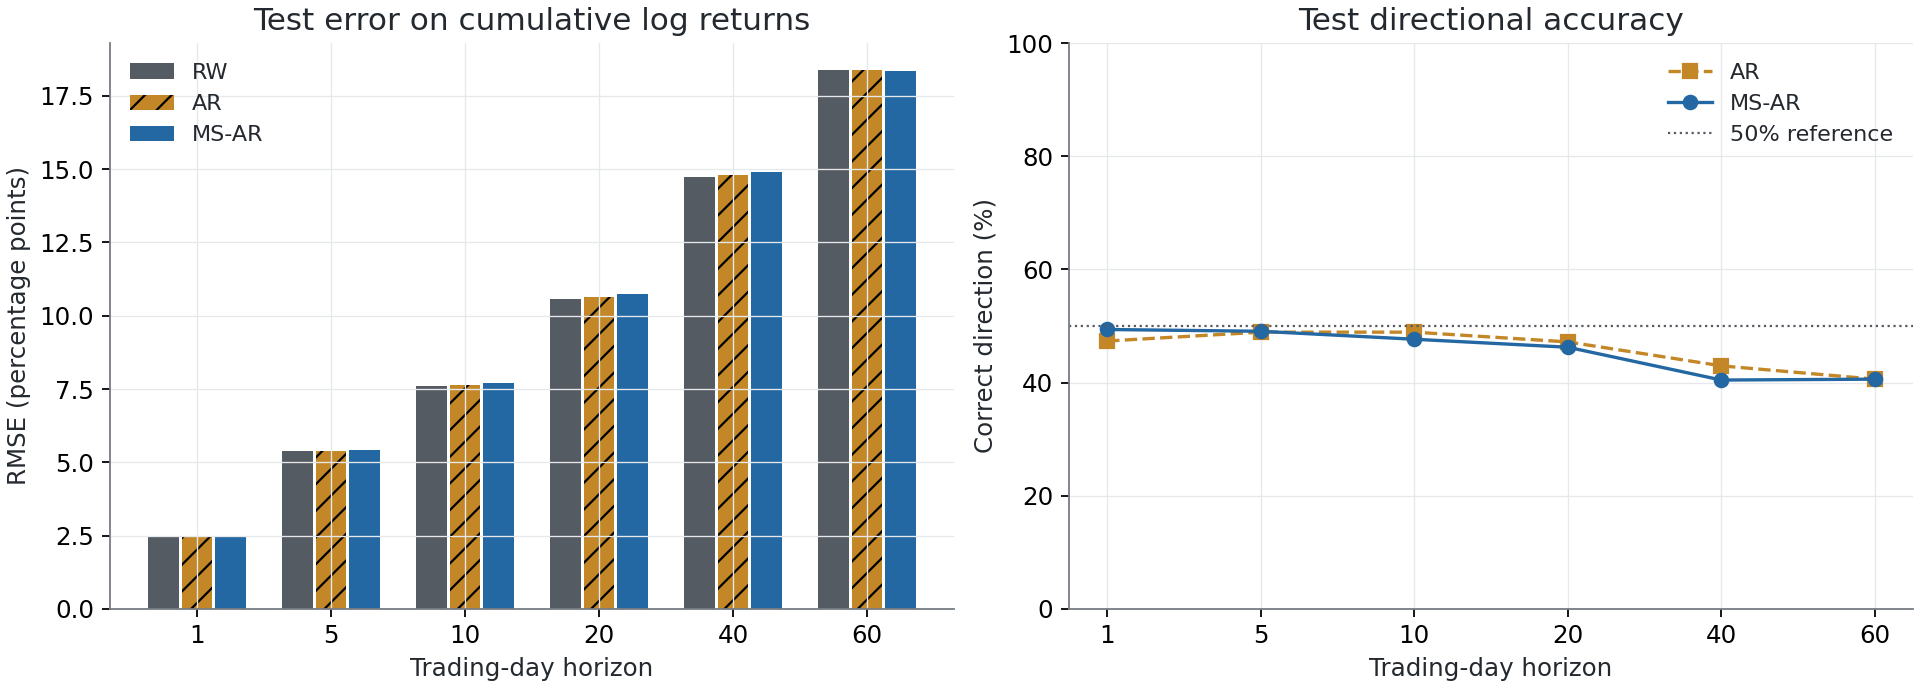

In [27]:
display(Image(filename=str(OUTPUTS / "figures" / "accuracy.png")))

#### Robustness across market conditions and years

These tables retain each horizon. The volatility split uses observable
rolling 20-session return standard deviation at the forecast origin and
a median threshold estimated strictly before validation. It therefore
avoids classifying forecasts using future volatility. These subsets are
descriptive comparisons and can contain fewer observations.

In [28]:
by_condition = pd.read_csv(OUTPUTS / "metrics_by_condition.csv")
threshold = summary["volatility_split_threshold_pct"]
display(Markdown(f"**Volatility threshold:** {threshold:.3f}% daily log-return SD."))
condition_table = by_condition.pivot(index=["condition", "horizon"],
                                    columns="model", values="return_rmse_pct")
condition_table = condition_table.rename_axis(columns=None).reset_index()
show_table(condition_table.rename(columns={"condition": "Origin condition", "horizon": "Sessions"}), precision=3)
display(Markdown("**Return RMSE by forecast-origin year (percentage points)**"))
by_year = pd.read_csv(OUTPUTS / "metrics_by_year.csv")
year_table = by_year.pivot(index=["origin_year", "horizon"], columns="model", values="return_rmse_pct")
show_table(year_table.rename_axis(columns=None).reset_index()
           .rename(columns={"origin_year": "Origin year", "horizon": "Sessions"}), precision=3)

**Volatility threshold:** 1.743% daily log-return SD.

Origin condition,Sessions,AR,MS-AR,RW
higher_vol,1,3.187,3.185,3.177
higher_vol,5,6.776,6.812,6.748
higher_vol,10,9.886,9.957,9.845
higher_vol,20,14.206,14.296,14.160
higher_vol,40,19.072,19.107,18.993
higher_vol,60,20.215,20.115,20.214
lower_vol,1,1.564,1.564,1.564
lower_vol,5,3.832,3.853,3.841
lower_vol,10,4.954,5.055,4.957
lower_vol,20,6.041,6.240,6.006


**Return RMSE by forecast-origin year (percentage points)**

Origin year,Sessions,AR,MS-AR,RW
"2,024",1,1.678,1.678,1.669
"2,024",5,3.619,3.633,3.598
"2,024",10,4.301,4.339,4.281
"2,024",20,5.812,5.888,5.779
"2,024",40,7.105,7.213,6.951
"2,024",60,7.902,8.115,7.424
"2,025",1,1.811,1.806,1.811
"2,025",5,4.348,4.355,4.339
"2,025",10,5.440,5.543,5.396
"2,025",20,6.108,6.338,6.030


#### Learned regimes

These parameters belong to the final fit at the end of the snapshot.
Regime labels describe the fitted volatility levels. Filtered probability
in the figure is a probabilistic classification, not a certain label or
evidence that a particular event caused a switch.

In [29]:
regime_table = parameters.copy()
regime_table["Current probability (%)"] = 100 * regime_table.pop("current_probability")
show_table(regime_table.drop(columns="state_id").rename(columns={
    "regime": "Regime", "mean_parameter_pct": "Mean parameter (%)",
    "shock_sd_pct": "Shock SD (%)",
    "expected_duration_trading_days": "Expected duration (sessions)"}), precision=3)
display(Markdown("**Transition probabilities for the final fit**"))
transition_table = transitions.pivot(index="from_regime", columns="to_regime", values="probability")
display(transition_table.style.format("{:.3f}").set_caption("Rows: current regime; columns: next regime"))

Regime,Mean parameter (%),Shock SD (%),Expected duration (sessions),ar_lag1,Current probability (%)
low_vol,0.077,1.744,50.471,0.016,94.697
high_vol,-0.187,4.221,13.874,0.016,5.303


**Transition probabilities for the final fit**

to_regime,high_vol,low_vol
from_regime,,
high_vol,0.928,0.072
low_vol,0.020,0.980


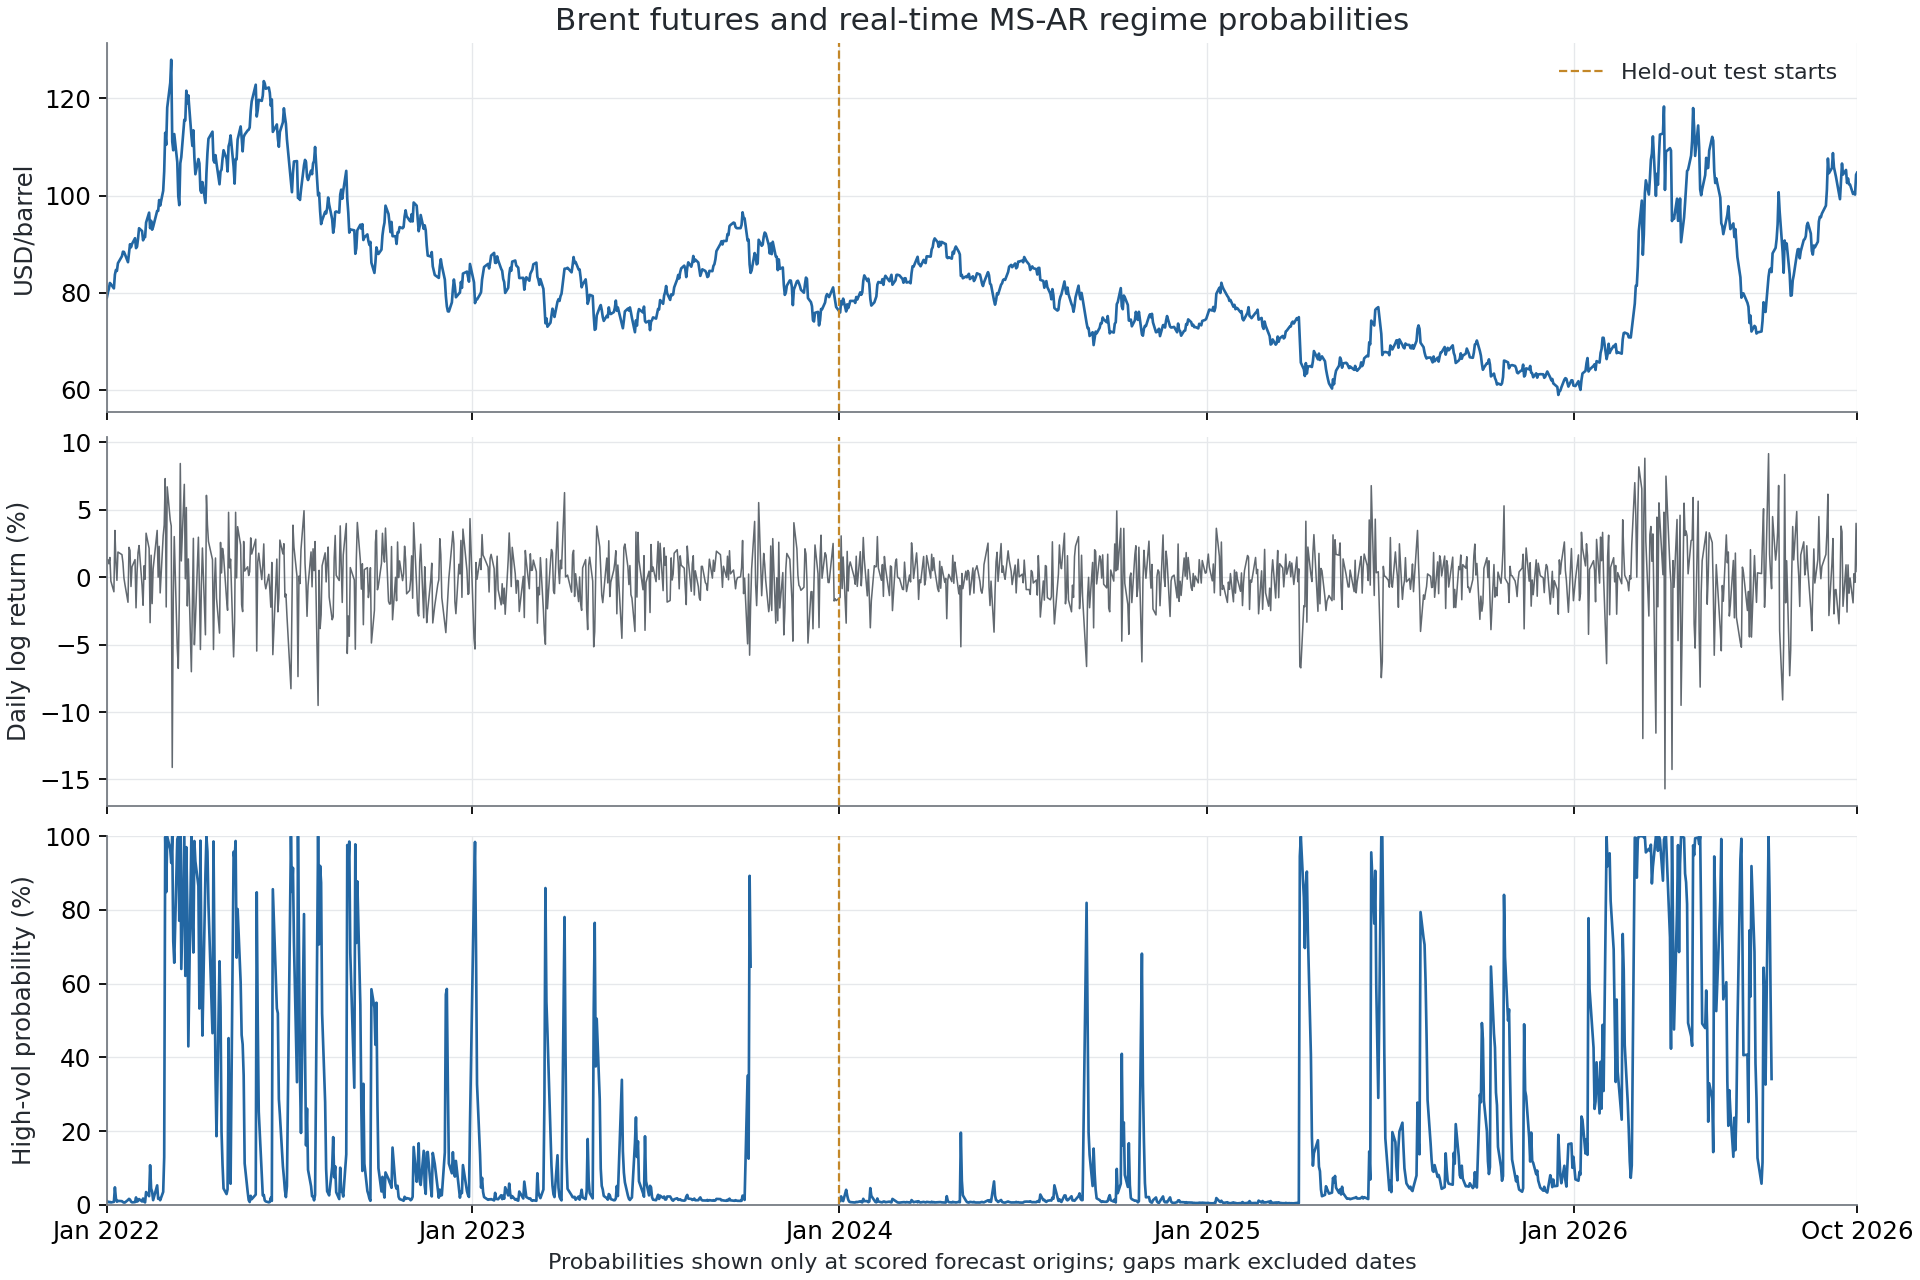

In [30]:
display(Image(filename=str(OUTPUTS / "figures" / "regimes.png")))

#### Forecast at the final observed session

Prices and bounds are USD per barrel. The interval is a prediction
interval for a future price conditional on fitted parameters, rather than
a confidence interval for an estimated mean. No later observations are
used in these forecasts. Forecast dates, where shown, are approximate
business dates; the horizons are trading-session counts.

In [31]:
point_table = latest[["asof_date", "horizon", "indicative_business_date", "forecast_return",
                      "forecast_price", "expected_price", "price_median"]].copy()
point_table["forecast_return"] *= 100
show_table(point_table.rename(columns={
    "asof_date": "Origin", "horizon": "Sessions", "indicative_business_date": "Indicative date",
    "forecast_return": "Mean cumulative log return (%)",
    "forecast_price": "Price implied by mean log return ($)",
    "expected_price": "Expected arithmetic price ($)", "price_median": "Simulated median ($)"}), precision=3)
display(Markdown("**Conditional prediction intervals and future regime probabilities**"))
interval_table = latest[["horizon", "price_lo95", "price_lo80", "price_hi80", "price_hi95",
                         "high_vol_probability"]].copy()
interval_table["high_vol_probability"] *= 100
show_table(interval_table.rename(columns={
    "horizon": "Sessions", "price_lo95": "95% lower ($)", "price_lo80": "80% lower ($)",
    "price_hi80": "80% upper ($)", "price_hi95": "95% upper ($)",
    "high_vol_probability": "High-vol probability (%)"}), precision=3)

Origin,Sessions,Indicative date,Mean cumulative log return (%),Price implied by mean log return ($),Expected arithmetic price ($),Simulated median ($)
2026-10-09,1,2026-10-12,0.065,104.788,104.786,104.775
2026-10-09,5,2026-10-16,0.268,105.001,105.077,105.049
2026-10-09,10,2026-10-23,0.468,105.212,105.425,105.337
2026-10-09,20,2026-11-06,0.768,105.528,106.050,105.772
2026-10-09,40,2026-12-04,1.220,106.006,107.261,106.590
2026-10-09,60,2027-01-01,1.627,106.438,108.307,107.046


**Conditional prediction intervals and future regime probabilities**

Sessions,95% lower ($),80% lower ($),80% upper ($),95% upper ($),High-vol probability (%)
1,100.751,102.310,107.298,108.832,6.797
5,95.418,99.287,110.945,114.831,11.521
10,90.955,96.886,114.159,120.027,15.361
20,84.507,93.190,119.185,128.425,19.197
40,76.341,87.993,127.233,142.004,21.218
60,71.071,83.781,133.895,153.271,21.512


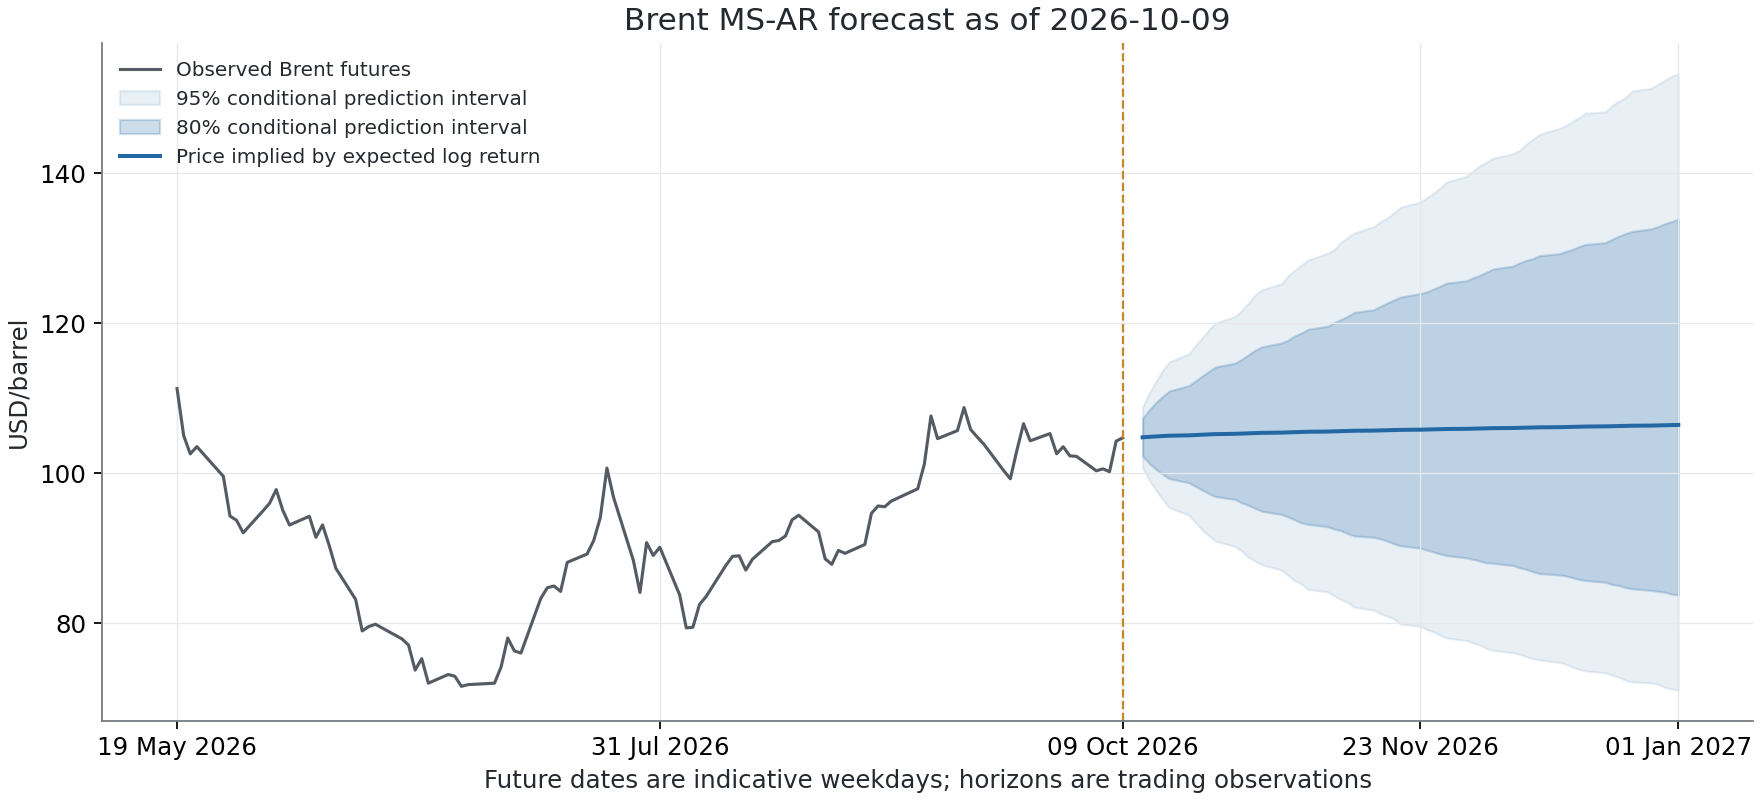

In [32]:
display(Image(filename=str(OUTPUTS / "figures" / "latest_forecast.png")))

### Takeaways

In [33]:
observations = []
if not comparison.empty:
    improvements = comparison["MS-AR RMSE improvement vs RW (%)"]
    for horizon, improvement in improvements.items():
        direction = "lower" if improvement >= 0 else "higher"
        observations.append(f"At **{int(horizon)} sessions**, MS-AR price RMSE is "
                            f"**{abs(improvement):.2f}% {direction}** than RW.")
    if (improvements > 0).all():
        observations.append("MS-AR improves on RW at each tested horizon in this test "
                            "sample. This result does not establish performance in a future sample.")
    elif (improvements <= 0).all():
        observations.append("The fitted regime structure does not deliver a price-RMSE "
                            "improvement over RW in this test sample.")
    else:
        observations.append("The price-accuracy result varies by horizon; regime detection "
                            "does not produce a uniform forecast improvement in this sample.")
observations.append("Regime probabilities can still describe changing return variability. "
                    "That descriptive value should be distinguished from evidence of "
                    "better price forecasting.")
observations.append("The next useful check is a fresh historical-data update followed by "
                    "the same prespecified selection and evaluation procedure.")
display(Markdown("\n\n".join("- " + item for item in observations)))

- At **1 sessions**, MS-AR price RMSE is **0.19% higher** than RW.

- At **5 sessions**, MS-AR price RMSE is **0.83% higher** than RW.

- At **10 sessions**, MS-AR price RMSE is **1.23% higher** than RW.

- At **20 sessions**, MS-AR price RMSE is **1.35% higher** than RW.

- At **40 sessions**, MS-AR price RMSE is **1.53% higher** than RW.

- At **60 sessions**, MS-AR price RMSE is **0.13% higher** than RW.

- The fitted regime structure does not deliver a price-RMSE improvement over RW in this test sample.

- Regime probabilities can still describe changing return variability. That descriptive value should be distinguished from evidence of better price forecasting.

- The next useful check is a fresh historical-data update followed by the same prespecified selection and evaluation procedure.

#### Inspectable evidence

`Outputs/msar/baseline/` retains validation scores, forecast metrics, final forecasts,
regime parameters, transitions, input quality/provenance, and the exact
run summary. The implementation cells above contain the model, simulation and backtest
logic. The saved notebook embeds executed figures and tables for reading
without a kernel.

In [34]:
verification = json.loads((OUTPUTS / "verification.json").read_text(encoding="utf-8"))
display(Markdown("**Forecast implementation checks:** exact one-step state enumeration "
                 f"agrees with the moment recursion: **{verification['one_step_enumeration_passed']}**. "
                 "The table compares the exact mean with 100,000 independently simulated paths "
                 "at 1, 5 and 60 sessions. Differences are measured in simulation standard errors."))
show_table(pd.DataFrame(verification["simulation_mean_checks"]), precision=6)
independent_path = OUTPUTS / "independent_checks.json"
if independent_path.exists():
    independent = json.loads(independent_path.read_text(encoding="utf-8"))
    display(Markdown("**Independent synthetic implementation audit:** "
        f"{independent['status']}. Exhaustive state-path enumeration at horizons 1–6 "
        f"agrees with exact recursion to "
        f"{independent['maximum_absolute_enumeration_discrepancy']:.2e} "
        "cumulative-log-return units. Repeated fitting with the same seed "
        f"returns identical parameters: **{independent['seeded_fitting']['same_seed_identical_parameters']}**."))

**Forecast implementation checks:** exact one-step state enumeration agrees with the moment recursion: **True**. The table compares the exact mean with 100,000 independently simulated paths at 1, 5 and 60 sessions. Differences are measured in simulation standard errors.

horizon,exact_mean_log_return,simulation_mean,simulation_mc_se,absolute_z
1,0.000648,0.000742,0.000063,1.479912
5,0.002682,0.002765,0.000152,0.546203
60,0.016273,0.014739,0.000611,2.512991


**Independent synthetic implementation audit:** passed. Exhaustive state-path enumeration at horizons 1–6 agrees with exact recursion to 5.64e-18 cumulative-log-return units. Repeated fitting with the same seed returns identical parameters: **True**.

<a id="extended-experiment"></a>

## Conservative MS-AR and MS-ARX experiment

**Exploratory follow-up:** this experiment reuses the 2024+ test sample
already inspected in version 1. Its results are useful for development;
they are not a fresh confirmation of predictive performance. The original
baseline evidence is retained in the same project.

### Key results

The observed comparisons and selected settings below come from the saved
version-two run. RW is the no-change price forecast. When the selected
shrinkage weight is zero, the model's point forecast equals RW exactly.

In [35]:
config = extended_config
OUTPUTS = config.output_dir
summary_path = OUTPUTS / "run_summary.json"
if not summary_path.is_file():
    raise FileNotFoundError("Set RERUN_MODEL = True and run all cells to create the follow-up evidence.")
summary = json.loads(summary_path.read_text(encoding="utf-8"))
metrics = pd.read_csv(OUTPUTS / "metrics.csv")
extended_latest = pd.read_csv(OUTPUTS / "latest_forecasts.csv")
selected = summary["selected_models"]
artifacts = json.loads((OUTPUTS / "latest_model_artifacts.json").read_text(encoding="utf-8"))

def show_table(frame, precision=3):
    numeric = frame.select_dtypes(include="number").columns
    formats = {c: ("{:,.0f}" if pd.api.types.is_integer_dtype(frame[c])
                   else "{:,." + str(precision) + "f}") for c in numeric}
    display(frame.style.format(formats, na_rep="—").hide(axis="index"))

def compact_json(mapping, prefix=""):
    rows = []
    for key, value in mapping.items():
        label = prefix + key
        if isinstance(value, dict):
            rows.extend(compact_json(value, label + "."))
        elif isinstance(value, list):
            rows.append((label, ", ".join(map(str, value))))
        else:
            rows.append((label, value))
    return rows

def read_optional(name):
    path = OUTPUTS / name
    return pd.read_csv(path) if path.is_file() else None

def compare_rmse(metric_column):
    result = metrics.pivot(index="horizon", columns="model", values=metric_column)
    for name in list(result.columns):
        if name != "RW":
            result[name + " vs RW (%)"] = 100 * (1 - result[name] / result["RW"])
    return result.rename_axis(columns=None).reset_index()

In [36]:
return_comparison = compare_rmse("return_rmse_pct")
price_comparison = compare_rmse("price_rmse_usd")
observations = []
observations.append(f"**Validation:** {summary['n_validation_origins']:,} origins from "
                    f"{summary['validation_first_origin']} to {summary['validation_last_origin']}. "
                    f"**Reused exploratory test:** {summary['n_test_origins']:,} origins from "
                    f"{summary['test_first_origin']} to {summary['test_last_origin']}.")
for family, choice in selected.items():
    equivalent = "; point forecast is exactly RW" if choice["mean_weight"] == 0 else ""
    observations.append(f"**Selected {family}:** mean mode `{choice['mean_mode']}`, "
                        f"{choice['window']} sessions, refit every {choice['refit_every']} "
                        f"sessions, mean weight **{choice['mean_weight']:g}**{equivalent}. "
                        f"Validation RMSE-ratio score **{choice['validation_score']:.6f}**.")
observations.append(f"**Preferred family by validation:** "
                    f"`{summary['preferred_family_by_validation']}`. "
                    f"**Latest data:** {summary['latest_asof']}; "
                    f"Brent **${summary['latest_price']:.2f}/barrel**.")
for model in metrics.model.unique():
    if model == "RW":
        continue
    gains = return_comparison[model + " vs RW (%)"]
    price_gains = price_comparison[model + " vs RW (%)"]
    wins = int((gains > 1e-9).sum())
    ties = int(np.isclose(gains, 0, atol=1e-9).sum())
    price_wins = int((price_gains > 1e-9).sum())
    observations.append(f"**{model}:** return RMSE beats RW at **{wins}/{len(gains)} "
                        f"horizons**, ties at **{ties}/{len(gains)}**; "
                        f"price RMSE beats RW at **{price_wins}/{len(gains)}**.")
observations.append("**Interpretation:** improvements on this reused test sample are "
                    "exploratory and require a later untouched sample for confirmation.")
observations.append("**Prediction intervals:** Gaussian return and regime uncertainty is "
                    "retained. Shrinkage shifts the mean while leaving simulated noise "
                    "unshrunk; it does not make the intervals falsely narrower. MS-ARX "
                    "intervals condition on the specified future predictor scenario and "
                    "exclude predictor and parameter uncertainty.")
display(Markdown("\n\n".join("- " + s for s in observations)))

- **Validation:** 442 origins from 2022-01-03 to 2023-10-05. **Reused exploratory test:** 638 origins from 2024-01-02 to 2026-07-16.

- **Selected conservative:** mean mode `zero`, 1260 sessions, refit every 63 sessions, mean weight **0**; point forecast is exactly RW. Validation RMSE-ratio score **1.000000**.

- **Selected msarx:** mean mode `shared`, 756 sessions, refit every 63 sessions, mean weight **0.25**. Validation RMSE-ratio score **0.983446**.

- **Preferred family by validation:** `msarx`. **Latest data:** 2026-10-09; Brent **$104.72/barrel**.

- **ARX:** return RMSE beats RW at **1/6 horizons**, ties at **0/6**; price RMSE beats RW at **1/6**.

- **V1 MS-AR:** return RMSE beats RW at **1/6 horizons**, ties at **0/6**; price RMSE beats RW at **0/6**.

- **V2 MS-ARX:** return RMSE beats RW at **1/6 horizons**, ties at **0/6**; price RMSE beats RW at **1/6**.

- **V2 conservative:** return RMSE beats RW at **0/6 horizons**, ties at **6/6**; price RMSE beats RW at **0/6**.

- **Interpretation:** improvements on this reused test sample are exploratory and require a later untouched sample for confirmation.

- **Prediction intervals:** Gaussian return and regime uncertainty is retained. Shrinkage shifts the mean while leaving simulated noise unshrunk; it does not make the intervals falsely narrower. MS-ARX intervals condition on the specified future predictor scenario and exclude predictor and parameter uncertainty.

### Context & Methods

Version 1 found little improvement over a no-change forecast. Version 2
examines two targeted changes: conservatively shrink the MS-AR expected
cumulative log return toward zero, and add a small set of lagged predictors
in an MS-ARX model. Settings are selected using chronological validation,
with the test sample reused only for exploratory comparison.

Both new models use AR(1) with a shared AR coefficient and switching
innovation variances. Conservative MS-AR varies its mean structure:
switching intercepts, a shared intercept, or zero intercept. MS-ARX has
a shared intercept and shared coefficients for lagged WTI dollar change,
DXY log return and Brent–WTI dollar spread. Its regimes affect variance
and estimation; they do not have separate predictor-response equations.

The ordinary ARX control uses the selected MS-ARX window, refit dates,
scaler, input path and shrinkage weight. The raw comparison also shows
both ARX models before shrinkage, so a zero mean weight does not hide
their underlying forecasting differences.

#### Key Assumptions

- Both versions retain hidden Markov regimes and Gaussian return innovations.
- A shrinkage weight $\lambda$ scales the exact expected cumulative log return.
  At $\lambda=0$, the point price forecast is the observed price at the origin.
- The simulated return paths are center-shifted to the shrunk exact mean;
  simulated return and regime noise is not multiplied by $\lambda$.
- Future predictors are scenarios supplied by the forecasting routine.
  Their future realization is unknown, and predictor uncertainty is excluded.
- The first future predictor vector uses values known at the origin.
  Later WTI changes and DXY returns are zero, with the origin oil-price
  spread frozen. This is a conditional input path, not a coherent joint
  Brent/WTI price scenario.
- Overlapping forecast errors make the reported improvements descriptive.
  Reusing the previously examined test period means it is not an independent
  out-of-sample confirmation of the version-two design.
- The local unadjusted front-month futures snapshot retains contract-roll jumps.
- Daily quotes aligned by date are assumed available after the origin close.
  The source does not independently establish intraday release/close alignment.
- Student-t errors and separate interval recalibration are not part of this round.

The follow-up implementation cells above contain estimation, scenario construction,
selection and evaluation logic. [Statsmodels' Markov-switching documentation](https://www.statsmodels.org/stable/generated/statsmodels.tsa.regime_switching.markov_autoregression.MarkovAutoregression.html)
describes the regime model used as the starting point.

#### Run settings and reproducibility

Set `RERUN_MODEL = True` in the setup cell and run all cells to repeat
both experiments in order. The default run reads the saved results.

In [37]:
show_table(pd.DataFrame(compact_json(summary["config"]), columns=["Saved run setting", "Value"]))
versions = pd.DataFrame([
    {"Package": name, "Run version": summary.get("versions", {}).get(name, "not recorded"),
     "Notebook version": importlib.metadata.version(name)}
    for name in ["numpy", "pandas", "scipy", "statsmodels", "matplotlib"]
])
show_table(versions)

Saved run setting,Value
input_path,C:\Users\uniqu\OneDrive\QF5210 Project\OilForecastQF\Data\raw\yahoo_daily.csv
output_dir,C:\Users\uniqu\OneDrive\QF5210 Project\OilForecastQF\standalone_msar\outputs_v2
original_dir,C:\Users\uniqu\OneDrive\QF5210 Project\OilForecastQF\standalone_msar\outputs
horizons,"1, 5, 10, 20, 40, 60"
windows,"504, 756, 1260"
refit_schedules,"21, 63"
weights,"0.0, 0.25, 0.5, 1.0"
validation_start,2022-01-01
test_start,2024-01-01
n_sim,3000


Package,Run version,Notebook version
numpy,1.24.3,1.24.3
pandas,2.2.3,2.2.3
scipy,1.10.1,1.10.1
statsmodels,0.15.0,0.15.0
matplotlib,3.7.1,3.7.1


### Data

Brent futures (`BZ=F`) are measured in USD per barrel. Daily log returns
use successive observed sessions. Missing prices are not interpolated.
The cached data and predictor diagnostics below document exactly the
source snapshot and predictor availability used in this run.

In [38]:
quality_path = OUTPUTS / "data_quality.json"
if quality_path.is_file():
    quality = json.loads(quality_path.read_text(encoding="utf-8"))
    show_table(pd.DataFrame(compact_json(quality), columns=["Input check / provenance", "Observed value"]))
panel = pd.read_csv(OUTPUTS / "input_panel.csv", parse_dates=["date"])
display(Markdown("**Latest source observations (prices are USD/barrel)**"))
show_table(panel[["date", "brent_fut", "wti_fut", "dxy"]].tail(6))
display(Markdown("**Lagged predictors used to explain the same dated return**"))
show_table(panel[["date", *["lagged_" + feature for feature in FEATURES]]].tail(6))

Input check / provenance,Observed value
source_path,C:\Users\uniqu\OneDrive\QF5210 Project\OilForecastQF\Data\raw\yahoo_daily.csv
source_sha256,b01eba9484f6e06d76053b6928764fada6b1c4e6665631aaf0f0ce639ba1cdc7
price_count,4779
first_date,2007-07-30
last_date,2026-10-09
source_tickers.brent_fut,BZ=F
source_tickers.wti_fut,CL=F
source_tickers.dxy,DX-Y.NYB
source_definition,Local Yahoo unadjusted front-month futures closes; contract-roll jumps retained
causally_filled_quote_counts.wti_fut,1


**Latest source observations (prices are USD/barrel)**

date,brent_fut,wti_fut,dxy
2026-10-02 00:00:00,102.250,91.110,101.930
2026-10-05 00:00:00,100.320,89.430,102.170
2026-10-06 00:00:00,100.580,89.440,101.830
2026-10-07 00:00:00,100.200,88.280,102.240
2026-10-08 00:00:00,104.280,91.490,102.140
2026-10-09 00:00:00,104.720,91.850,102.210


**Lagged predictors used to explain the same dated return**

date,lagged_wti_change_usd,lagged_dxy_log_return_pct,lagged_brent_wti_spread_usd
2026-10-02 00:00:00,2.450,0.639,9.440
2026-10-05 00:00:00,-1.760,-0.167,11.140
2026-10-06 00:00:00,-1.680,0.235,10.890
2026-10-07 00:00:00,0.010,-0.333,11.140
2026-10-08 00:00:00,-1.160,0.402,11.920
2026-10-09 00:00:00,3.210,-0.098,12.790


### Results

#### Validation settings and selection costs

Validation determines all model choices before evaluating version-two test
forecasts. The saved score grids expose the candidate settings, scores and
fitting costs. RW remains available through zero forecast-mean shrinkage. Selecting
that setting is evidence for a conservative no-change point forecast,
rather than a distinct price prediction that outperforms RW.

In [39]:
validation = pd.read_csv(OUTPUTS / "validation_scores.csv")
display(Markdown("**Validation mean RMSE-ratio grid (lower is better; RW = 1)**"))
grid = validation.pivot(index=["family", "mean_mode", "window", "refit_every"],
                        columns="mean_weight", values="validation_score")
grid.columns = [f"Mean weight {weight:g}" for weight in grid.columns]
show_table(grid.reset_index(), precision=6)
display(Markdown("**Selected settings and declared tie rule**"))
selected_frame = pd.DataFrame(selected.values())
choice_columns = ["family", "mean_mode", "window", "refit_every", "mean_weight",
                  "validation_score", "validation_improvement_vs_rw_pct"]
show_table(selected_frame[choice_columns], precision=6)
display(Markdown(summary["tie_rule"]))
fit_log = json.loads((OUTPUTS / "fit_log.json").read_text(encoding="utf-8"))
fitting_cost = pd.DataFrame([
    {"path": event["path"], "optimizer_starts": len(event["attempts"])}
    for event in fit_log if event["phase"] == "validation"
]).groupby("path").agg(validation_refits=("optimizer_starts", "size"),
                      optimizer_starts=("optimizer_starts", "sum")).reset_index()
display(Markdown("**Validation fitting costs** (reused fit logs count the underlying "
                 "fits even when a checked cache is reused; weights share each fitted path)."))
show_table(fitting_cost)
display(Markdown(f"Completed **{summary['n_fitting_paths_completed']}/"
                 f"{summary['n_fitting_paths_planned']}** planned fitting paths; "
                 f"**{summary['n_scored_weight_combinations']}** scored path/weight combinations; "
                 f"**{summary['n_rejected_paths']}** rejected paths. Current-run wall time: "
                 f"**{summary['elapsed_seconds']:.1f} seconds**; this is not a per-path "
                 "fresh-fit timing because checked caches may be reused."))
failures = json.loads((OUTPUTS / "candidate_failures.json").read_text(encoding="utf-8"))
if failures:
    display(Markdown("**Rejected fitting paths**; full diagnostics remain in `candidate_failures.json`."))
    show_table(pd.DataFrame([{**f, "error": f["error"][:240]} for f in failures]))

**Validation mean RMSE-ratio grid (lower is better; RW = 1)**

family,mean_mode,window,refit_every,Mean weight 0,Mean weight 0.25,Mean weight 0.5,Mean weight 1
conservative,shared,504,21,1.000000,1.030343,1.077451,1.208025
conservative,shared,504,63,1.000000,1.029147,1.074595,1.201165
conservative,shared,756,21,1.000000,1.016136,1.044493,1.130456
conservative,shared,756,63,1.000000,1.013106,1.037881,1.115958
conservative,shared,"1,260",21,1.000000,1.014355,1.036628,1.100934
conservative,shared,"1,260",63,1.000000,1.012841,1.033705,1.095621
conservative,switching,504,21,1.000000,1.018873,1.042622,1.102404
conservative,switching,504,63,1.000000,1.019678,1.044567,1.107541
conservative,switching,756,21,1.000000,1.006351,1.015572,1.042150
conservative,switching,756,63,1.000000,1.002239,1.007504,1.026816


**Selected settings and declared tie rule**

family,mean_mode,window,refit_every,mean_weight,validation_score,validation_improvement_vs_rw_pct
conservative,zero,"1,260",63,0.000000,1.000000,0.000000
msarx,shared,756,63,0.250000,0.983446,1.655441


Scores within1e-10: smaller mean weight, longer window, slower refit, fewer mean parameters; overall prefer conservative on ties

**Validation fitting costs** (reused fit logs count the underlying fits even when a checked cache is reused; weights share each fitted path).

path,validation_refits,optimizer_starts
conservative-shared-w1260-r21,22,44
conservative-shared-w1260-r63,8,16
conservative-shared-w504-r21,22,44
conservative-shared-w504-r63,8,16
conservative-shared-w756-r21,22,44
conservative-shared-w756-r63,8,16
conservative-switching-w1260-r21,22,44
conservative-switching-w1260-r63,8,16
conservative-switching-w504-r21,22,44
conservative-switching-w504-r63,8,16


Completed **24/24** planned fitting paths; **96** scored path/weight combinations; **0** rejected paths. Current-run wall time: **1149.6 seconds**; this is not a per-path fresh-fit timing because checked caches may be reused.

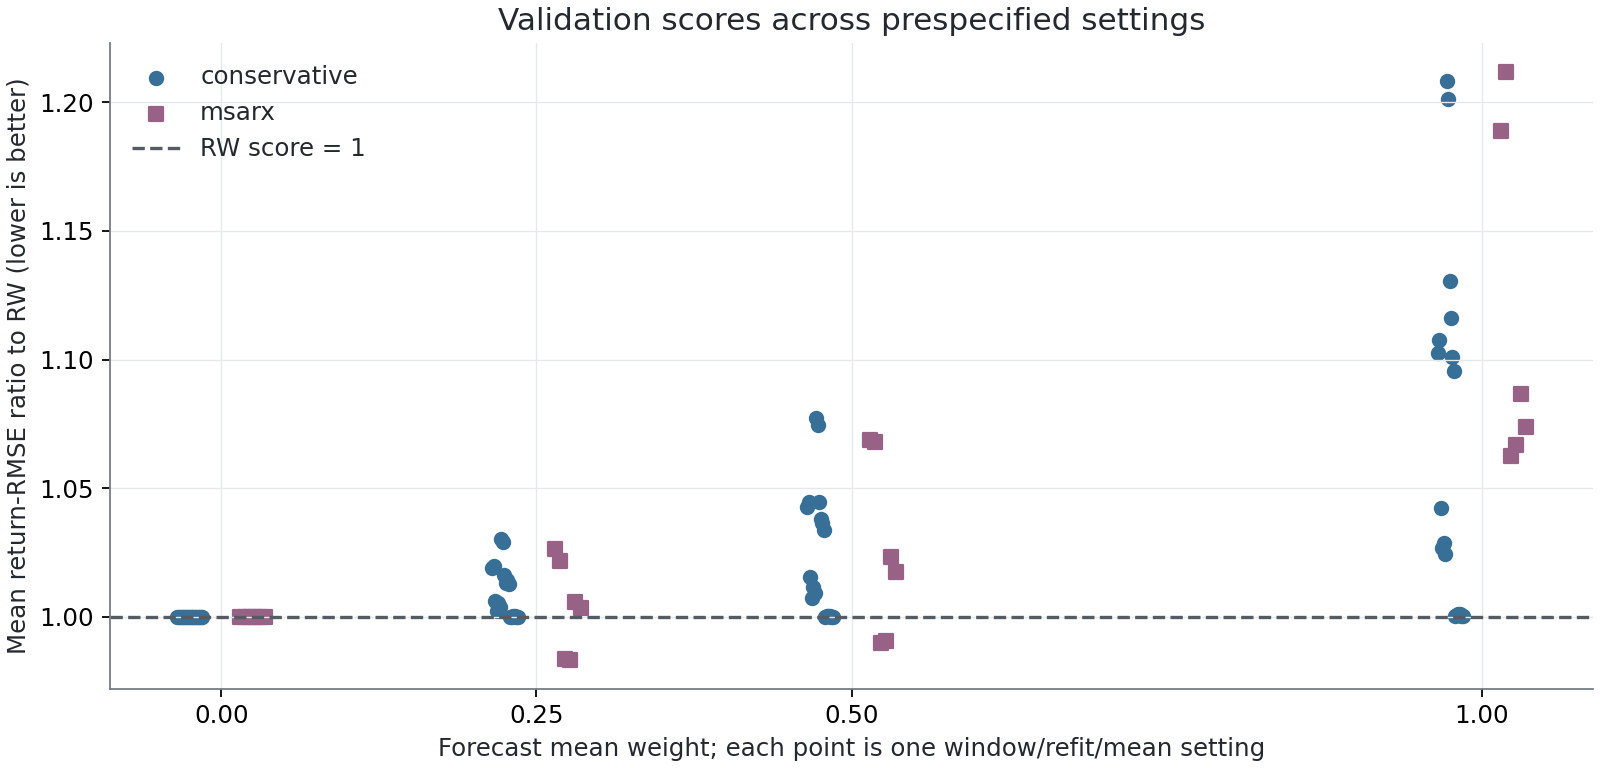

In [40]:
display(Image(filename=str(OUTPUTS / "figures" / "validation.png")))

#### Common-origin comparison: original MS-AR, conservative MS-AR, MS-ARX and RW

Return RMSE is in percentage points of cumulative log return; price RMSE
is USD per barrel. All compared forecasts use the same test origins and
horizons. Positive improvement means lower error than RW. Exact ties
produced by a zero shrinkage weight are retained as ties.
ARX is a single-regime control using the selected MS-ARX settings and
shrinkage weight; it has not received an independent hyperparameter search.

In [41]:
display(Markdown("**Cumulative-return RMSE and improvement versus RW**"))
model_order = ["RW", "V1 MS-AR", "V2 conservative", "V2 MS-ARX", "ARX"]
show_table(return_comparison[["horizon", *model_order]])
gain_columns = [model + " vs RW (%)" for model in model_order if model != "RW"]
show_table(return_comparison[["horizon", *gain_columns]].rename(columns={
    col: col.replace(" vs RW (%)", " improvement (%)") for col in gain_columns}))
display(Markdown("**Price RMSE and improvement versus RW**"))
show_table(price_comparison[["horizon", *model_order]])
show_table(price_comparison[["horizon", *gain_columns]].rename(columns={
    col: col.replace(" vs RW (%)", " improvement (%)") for col in gain_columns}))

**Cumulative-return RMSE and improvement versus RW**

horizon,RW,V1 MS-AR,V2 conservative,V2 MS-ARX,ARX
1,2.445,2.451,2.445,2.442,2.443
5,5.384,5.426,5.384,5.391,5.398
10,7.617,7.719,7.617,7.636,7.648
20,10.588,10.744,10.588,10.650,10.669
40,14.723,14.915,14.723,14.935,14.997
60,18.385,18.345,18.385,18.726,18.738


horizon,V1 MS-AR improvement (%),V2 conservative improvement (%),V2 MS-ARX improvement (%),ARX improvement (%)
1,-0.216,-0.000,0.149,0.099
5,-0.782,-0.000,-0.131,-0.271
10,-1.328,-0.000,-0.248,-0.396
20,-1.475,-0.000,-0.582,-0.765
40,-1.305,-0.000,-1.438,-1.858
60,0.216,-0.000,-1.858,-1.923


**Price RMSE and improvement versus RW**

horizon,RW,V1 MS-AR,V2 conservative,V2 MS-ARX,ARX
1,2.154,2.158,2.154,2.149,2.150
5,4.546,4.584,4.546,4.553,4.559
10,6.447,6.526,6.447,6.463,6.467
20,8.975,9.096,8.975,9.021,9.023
40,12.369,12.559,12.369,12.523,12.543
60,15.386,15.406,15.386,15.633,15.576


horizon,V1 MS-AR improvement (%),V2 conservative improvement (%),V2 MS-ARX improvement (%),ARX improvement (%)
1,-0.194,0.000,0.229,0.181
5,-0.831,0.000,-0.154,-0.299
10,-1.228,0.000,-0.258,-0.323
20,-1.353,0.000,-0.512,-0.540
40,-1.534,0.000,-1.245,-1.408
60,-0.131,0.000,-1.610,-1.237


In [42]:
details = [c for c in ["model", "horizon", "n_forecasts", "return_mae_pct",
                       "directional_accuracy_pct", "directional_prediction_share_pct",
                       "coverage80_pct", "coverage95_pct"] if c in metrics]
show_table(metrics[details])

model,horizon,n_forecasts,return_mae_pct,directional_accuracy_pct,directional_prediction_share_pct,coverage80_pct,coverage95_pct
ARX,1,638,1.669,48.589,100.000,—,—
RW,1,638,1.667,—,0.000,—,—
V1 MS-AR,1,638,1.678,49.373,100.000,81.661,94.514
V2 MS-ARX,1,638,1.667,49.530,100.000,79.781,93.417
V2 conservative,1,638,1.667,—,0.000,81.191,94.828
ARX,5,638,3.829,46.552,100.000,—,—
RW,5,638,3.816,—,0.000,—,—
V1 MS-AR,5,638,3.854,49.060,100.000,82.602,93.887
V2 MS-ARX,5,638,3.823,49.060,100.000,77.743,90.596
V2 conservative,5,638,3.816,—,0.000,83.699,94.514


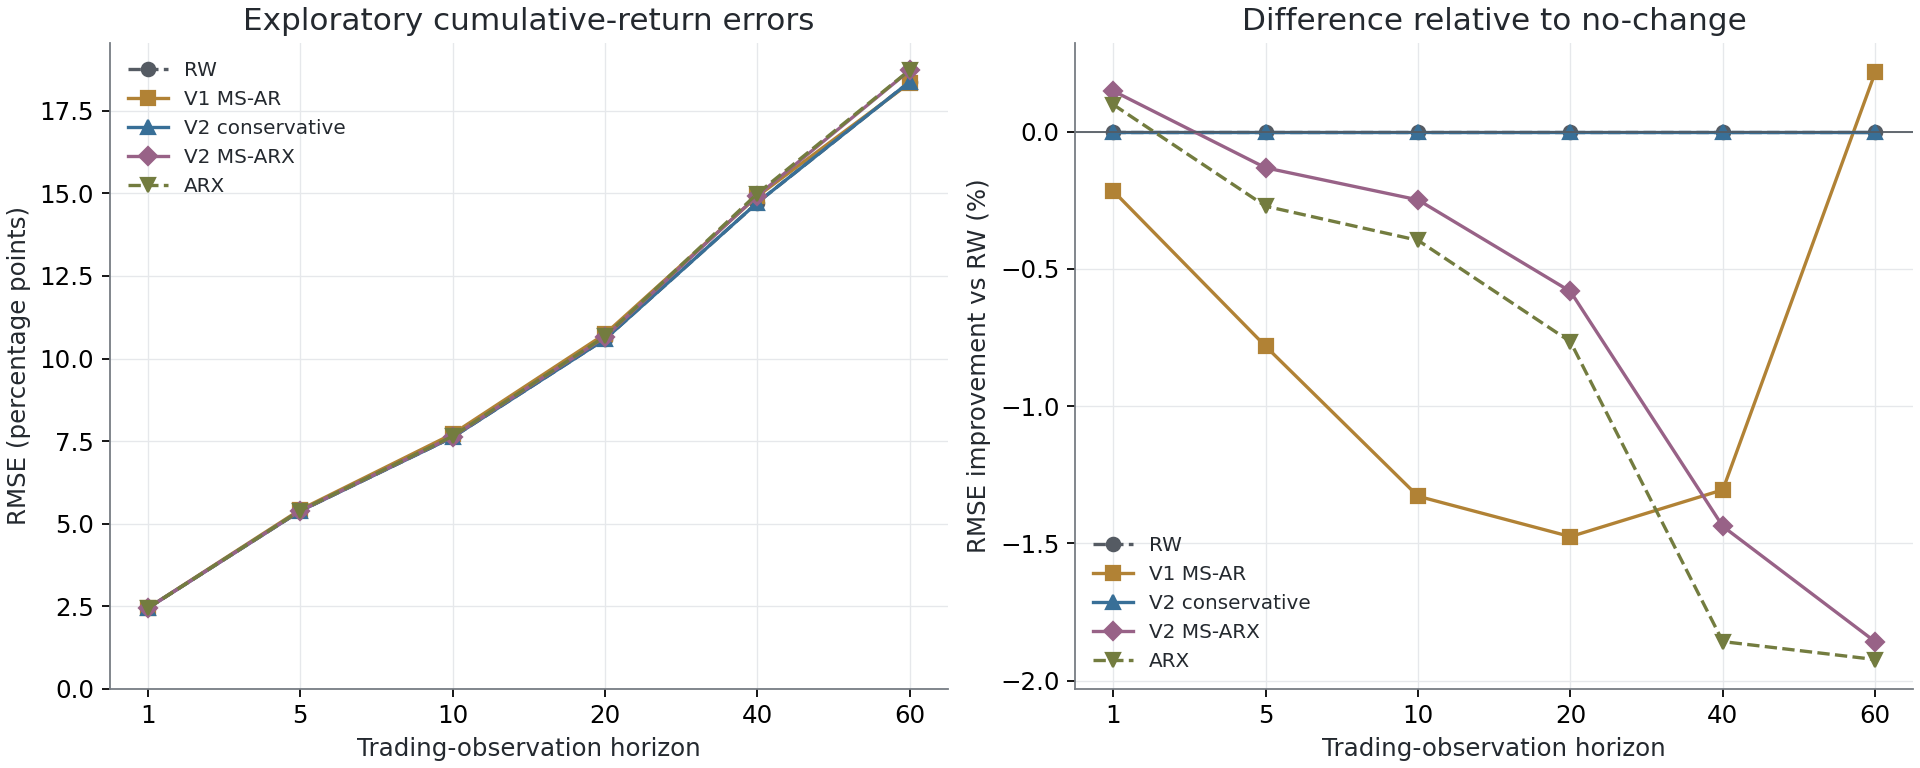

In [43]:
display(Image(filename=str(OUTPUTS / "figures" / "accuracy.png")))

#### Does MS-ARX add predictive value before shrinkage?

The raw comparison evaluates MS-ARX and ordinary ARX with a mean weight
of one. This helps distinguish the role of the regime model from the
effect of shrinking both forecasts toward RW. It remains exploratory.

In [44]:
raw_arx = pd.read_csv(OUTPUTS / "raw_arx_metrics.csv")
raw_table = raw_arx.pivot(index="horizon", columns="model", values="return_rmse_pct")
raw_table = raw_table.rename_axis(columns=None).reset_index()
show_table(raw_table, precision=4)

horizon,ARX,RW,V2 MS-ARX
1,2.4449,2.4455,2.4362
5,5.4672,5.3838,5.4335
10,7.7993,7.6175,7.7490
20,11.0763,10.5880,10.9881
40,16.2436,14.7231,15.9808
60,20.5712,18.3846,20.4703


#### Descriptive robustness

Each horizon is retained below. The market-condition split uses observed
20-session volatility at the origin and a threshold estimated before
validation. Forecasts are never classified using future volatility.

In [45]:
by_condition = pd.read_csv(OUTPUTS / "metrics_by_condition.csv")
condition_table = by_condition.pivot(index=["condition", "horizon"], columns="model", values="return_rmse_pct")
display(Markdown("**Cumulative-return RMSE by origin market condition (percentage points)**"))
show_table(condition_table.rename_axis(columns=None).reset_index())
by_year = pd.read_csv(OUTPUTS / "metrics_by_year.csv")
year_table = by_year.pivot(index=["origin_year", "horizon"], columns="model", values="return_rmse_pct")
display(Markdown("**Cumulative-return RMSE by forecast-origin year (percentage points)**"))
show_table(year_table.rename_axis(columns=None).reset_index())

**Cumulative-return RMSE by origin market condition (percentage points)**

condition,horizon,ARX,RW,V1 MS-AR,V2 MS-ARX,V2 conservative
higher_vol,1,3.173,3.177,3.185,3.171,3.177
higher_vol,5,6.778,6.748,6.812,6.762,6.748
higher_vol,10,9.889,9.845,9.957,9.861,9.845
higher_vol,20,14.225,14.160,14.296,14.175,14.160
higher_vol,40,19.131,18.993,19.107,18.988,18.993
higher_vol,60,20.336,20.214,20.115,20.237,20.214
lower_vol,1,1.563,1.564,1.564,1.563,1.564
lower_vol,5,3.833,3.841,3.853,3.839,3.841
lower_vol,10,4.968,4.957,5.055,4.984,4.957
lower_vol,20,6.139,6.006,6.240,6.176,6.006


**Cumulative-return RMSE by forecast-origin year (percentage points)**

origin_year,horizon,ARX,RW,V1 MS-AR,V2 MS-ARX,V2 conservative
"2,024",1,1.669,1.669,1.678,1.669,1.669
"2,024",5,3.608,3.598,3.633,3.606,3.598
"2,024",10,4.315,4.281,4.339,4.304,4.281
"2,024",20,5.886,5.779,5.888,5.864,5.779
"2,024",40,7.481,6.951,7.213,7.412,6.951
"2,024",60,8.290,7.424,8.115,8.361,7.424
"2,025",1,1.810,1.811,1.806,1.811,1.811
"2,025",5,4.340,4.339,4.355,4.350,4.339
"2,025",10,5.416,5.396,5.543,5.443,5.396
"2,025",20,6.167,6.030,6.338,6.243,6.030


#### Learned regimes at the final fit

Regime labels describe relative fitted shock volatility. They are
probabilistic classifications, and coefficient estimates do not establish
causal effects. MS-ARX coefficients correspond to fit-window standardized
predictors and are shared across its states.

In [46]:
parameters = pd.read_csv(OUTPUTS / "regime_parameters.csv")
parameter_display = parameters.copy()
parameter_display["current_probability_pct"] = 100 * parameter_display.pop("current_probability")
main_parameter_columns = ["model", "regime", "intercept_pct", "shock_sd_pct", "ar_lag1",
                          "current_probability_pct", "expected_duration_sessions"]
show_table(parameter_display[main_parameter_columns], precision=4)
beta_columns = [c for c in parameters if c.startswith("beta_")]
if beta_columns:
    display(Markdown("**Shared MS-ARX predictor coefficients** (daily return percentage points per standardized input)."))
    show_table(parameters[parameters.model == "V2 MS-ARX"][["model", "regime", *beta_columns]], precision=4)
transitions = pd.read_csv(OUTPUTS / "transitions.csv")
for model, table in transitions.groupby("model"):
    display(Markdown(f"**{model} transition matrix** — rows are current states, columns are next states."))
    display(table.pivot(index="from_regime", columns="to_regime", values="probability").style.format("{:.4f}"))

model,regime,intercept_pct,shock_sd_pct,ar_lag1,current_probability_pct,expected_duration_sessions
V2 conservative,low_vol,0.0000,1.7639,0.0178,94.9188,58.3255
V2 conservative,high_vol,0.0000,4.2440,0.0178,5.0812,15.4626
V2 MS-ARX,low_vol,0.0204,1.6528,-0.0860,94.6694,68.0138
V2 MS-ARX,high_vol,0.0204,4.3394,-0.0860,5.3306,18.3752


**Shared MS-ARX predictor coefficients** (daily return percentage points per standardized input).

model,regime,beta_wti_change_usd,beta_dxy_log_return_pct,beta_brent_wti_spread_usd
V2 MS-ARX,low_vol,0.1941,0.0213,0.0149
V2 MS-ARX,high_vol,0.1941,0.0213,0.0149


**V2 MS-ARX transition matrix** — rows are current states, columns are next states.

to_regime,high_vol,low_vol
from_regime,,
high_vol,0.9456,0.0544
low_vol,0.0147,0.9853


**V2 conservative transition matrix** — rows are current states, columns are next states.

to_regime,high_vol,low_vol
from_regime,,
high_vol,0.9353,0.0647
low_vol,0.0171,0.9829


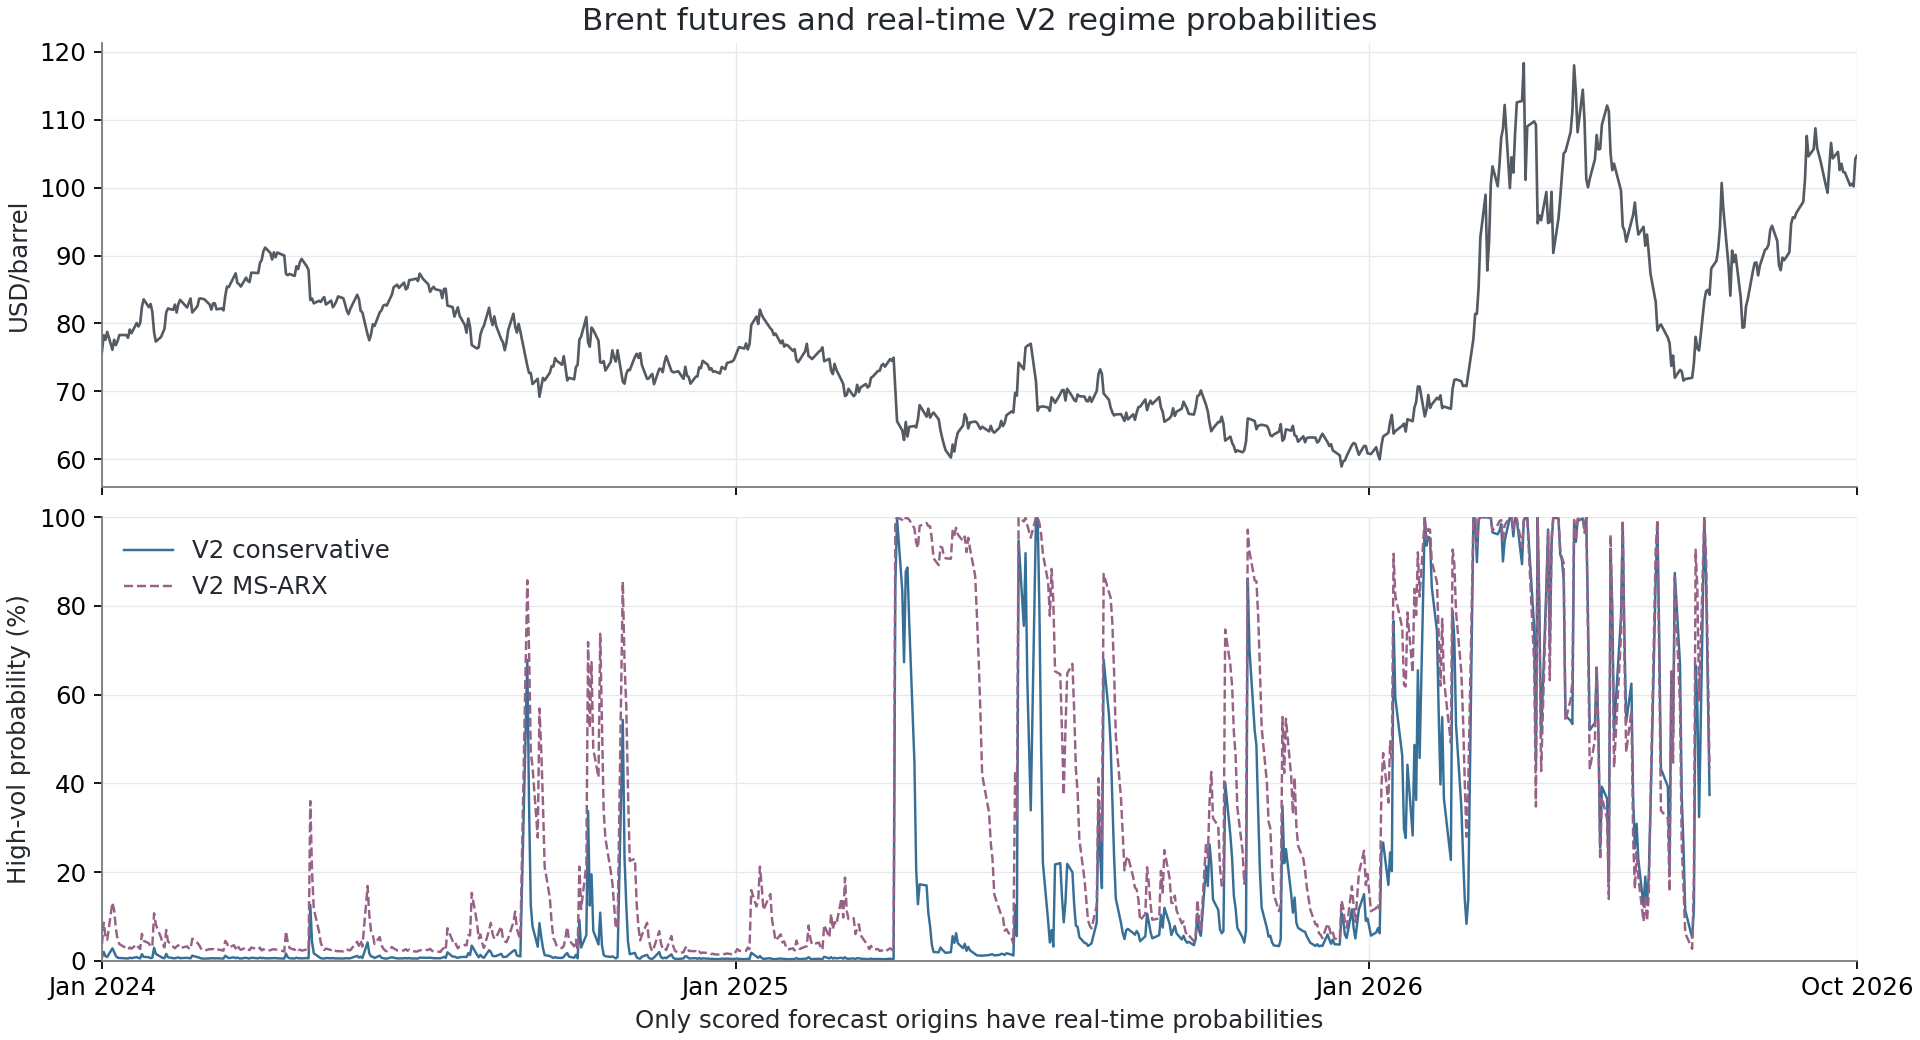

In [47]:
display(Image(filename=str(OUTPUTS / "figures" / "regimes.png")))

#### Forecast-origin scenario and latest forecasts

All prices and interval bounds below are USD per barrel. The principal
point price is implied by the model's expected cumulative log return;
it differs from the simulated arithmetic mean price. Future dates are
indicative weekdays, while horizons count observed trading sessions.
MS-ARX forecasts condition on the saved predictor scenario below.

In [48]:
display(Markdown("**Scenario definition:** " + summary["predictor_scenario"]))
arx_artifact = next(a for a in artifacts if a["model"] == "V2 MS-ARX")
future_raw = pd.DataFrame(arx_artifact["future_raw_X"], columns=FEATURES)
future_raw.insert(0, "Future step", np.arange(1, len(future_raw) + 1))
selected_steps = list(range(min(5, len(future_raw)))) + [len(future_raw) - 1]
selected_steps = sorted(set(selected_steps))
display(Markdown("**Raw future predictors** (first five and final vectors). "
                 "Changes are zero after step 1; the spread remains fixed as an input."))
show_table(future_raw.iloc[selected_steps])
future_scaled = pd.DataFrame(arx_artifact["future_standardized_X"], columns=FEATURES)
future_scaled.insert(0, "Future step", np.arange(1, len(future_scaled) + 1))
display(Markdown("**The same vectors after fit-window standardization**; raw zero "
                 "changes need not correspond to standardized zero values."))
show_table(future_scaled.iloc[selected_steps])
scaler_table = pd.DataFrame({
    "Predictor": FEATURES, "Fit-window mean": arx_artifact["scaler"]["means"],
    "Fit-window SD": arx_artifact["scaler"]["scales"],
    "Last observed standardized input X": arx_artifact["last_observed_X"]})
show_table(scaler_table, precision=4)
display(Markdown(f"**Latest MS-ARX estimation window:** "
                 f"{arx_artifact['train_start']} through {arx_artifact['train_end']}."))
for model, table in extended_latest.groupby("model"):
    weight = float(table.mean_weight.iloc[0])
    equivalence = " — exact no-change point forecast" if weight == 0 else ""
    display(Markdown(f"**{model}, mean weight {weight:g}{equivalence}**"))
    point_table = table[["horizon", "indicative_business_date", "raw_forecast_return",
                         "forecast_return", "forecast_price", "expected_price", "price_median"]].copy()
    point_table[["raw_forecast_return", "forecast_return"]] *= 100
    show_table(point_table.rename(columns={
        "horizon": "Sessions", "indicative_business_date": "Indicative date",
        "raw_forecast_return": "Raw mean log return (%)", "forecast_return": "Adjusted mean log return (%)",
        "forecast_price": "Log-mean point price ($)", "expected_price": "Arithmetic expected price ($)",
        "price_median": "Simulated median ($)"}))
    interval_table = table[["horizon", "price_lo95", "price_lo80", "price_hi80", "price_hi95",
                            "high_vol_probability"]].copy()
    interval_table["high_vol_probability"] *= 100
    show_table(interval_table.rename(columns={
        "horizon": "Sessions", "price_lo95": "95% lower ($)", "price_lo80": "80% lower ($)",
        "price_hi80": "80% upper ($)", "price_hi95": "95% upper ($)",
        "high_vol_probability": "High-vol probability (%)"}))

**Scenario definition:** First future inputs use origin-known WTI dollar change, DXY log return and Brent-WTI dollar spread. Thereafter changes=0 and spread frozen at origin. This is a conditional input path, not a coherent joint oil-price scenario.

**Raw future predictors** (first five and final vectors). Changes are zero after step 1; the spread remains fixed as an input.

Future step,wti_change_usd,dxy_log_return_pct,brent_wti_spread_usd
1,0.360,0.069,12.870
2,0.000,0.000,12.870
3,0.000,0.000,12.870
4,0.000,0.000,12.870
5,0.000,0.000,12.870
60,0.000,0.000,12.870


**The same vectors after fit-window standardization**; raw zero changes need not correspond to standardized zero values.

Future step,wti_change_usd,dxy_log_return_pct,brent_wti_spread_usd
1,0.162,0.183,4.433
2,-0.005,0.012,4.433
3,-0.005,0.012,4.433
4,-0.005,0.012,4.433
5,-0.005,0.012,4.433
60,-0.005,0.012,4.433


Predictor,Fit-window mean,Fit-window SD,Last observed standardized input X
wti_change_usd,0.0115,2.1553,1.4840
dxy_log_return_pct,-0.0050,0.4021,-0.2310
brent_wti_spread_usd,4.2536,1.9435,4.3923


... (3 outputs left out)

Sessions,95% lower ($),80% lower ($),80% upper ($),95% upper ($),High-vol probability (%)
1,100.928,102.398,107.128,108.641,6.432
5,96.600,99.858,110.009,113.630,10.129
10,93.041,97.816,112.594,118.208,13.483
20,87.693,94.684,116.735,125.810,17.466
40,80.557,90.217,123.567,138.954,20.362
60,75.683,86.702,129.607,149.018,21.054


**V2 conservative, mean weight 0 — exact no-change point forecast**

Sessions,Indicative date,Raw mean log return (%),Adjusted mean log return (%),Log-mean point price ($),Arithmetic expected price ($),Simulated median ($)
1,2026-10-12,0.007,0.000,104.720,104.717,104.697
5,2026-10-16,0.008,0.000,104.720,104.794,104.705
10,2026-10-23,0.008,0.000,104.720,104.926,104.703
20,2026-11-06,0.008,0.000,104.720,105.221,104.656
40,2026-12-04,0.008,0.000,104.720,105.926,104.675
60,2027-01-01,0.008,0.000,104.720,106.546,104.568


Sessions,95% lower ($),80% lower ($),80% upper ($),95% upper ($),High-vol probability (%)
1,100.715,102.229,107.241,108.803,6.380
5,95.454,99.004,110.662,114.677,10.596
10,91.253,96.472,113.611,119.855,14.195
20,85.350,92.670,118.202,128.343,18.076
40,77.407,87.280,125.383,142.271,20.433
60,71.939,83.117,131.822,153.042,20.861


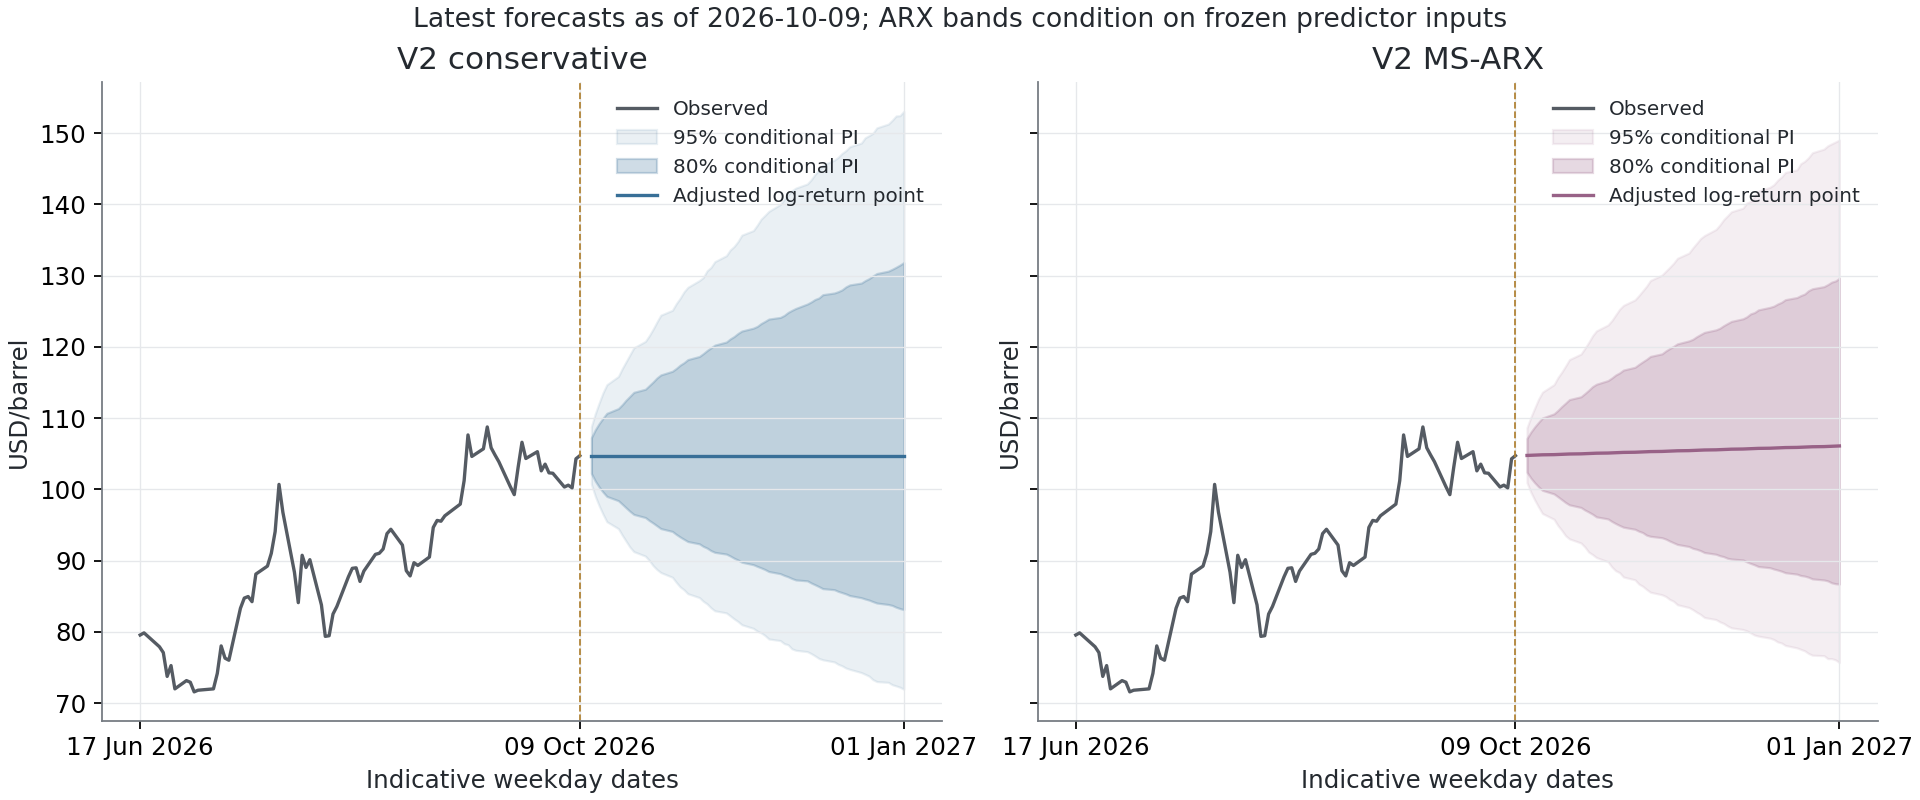

In [49]:
display(Image(filename=str(OUTPUTS / "figures" / "latest_forecast.png")))

### Takeaways

In [50]:
takeaways = []
for model in metrics.model.unique():
    if model == "RW":
        continue
    gains = return_comparison[model + " vs RW (%)"]
    takeaways.append(f"**{model}:** return-RMSE change versus RW ranges from "
                     f"**{gains.min():.2f}% to {gains.max():.2f}%** across horizons "
                     "(positive values indicate improvement).")
for family, choice in selected.items():
    if choice["mean_weight"] == 0:
        takeaways.append(f"The selected **{family}** weight is **0**. It yields RW "
                         "point forecasts exactly. Regimes and prediction intervals "
                         "remain estimated, but its price point forecasts are no-change.")
msarx_test = metrics[metrics.model == "V2 MS-ARX"].set_index("horizon")
rw_test = metrics[metrics.model == "RW"].set_index("horizon")
msarx_test_ratio = float((msarx_test.return_rmse_pct / rw_test.return_rmse_pct).mean())
validation_gain = 100 * (1 - selected["msarx"]["validation_score"])
first_gain = float(return_comparison.loc[return_comparison.horizon == 1,
                                        "V2 MS-ARX vs RW (%)"].iloc[0])
longer_gains = return_comparison.loc[return_comparison.horizon > 1, "V2 MS-ARX vs RW (%)"]
longer_worse = int((longer_gains < -1e-9).sum())
if validation_gain > 0 and msarx_test_ratio > 1:
    takeaways.append(f"**MS-ARX's {validation_gain:.2f}% validation gain does not "
                     f"generalize to this exploratory test:** its mean horizon-specific "
                     f"return-RMSE ratio is **{msarx_test_ratio:.8f}**, equivalent to "
                     f"**{100 * (msarx_test_ratio - 1):.2f}% higher error** than RW. "
                     f"Its 1-session return-RMSE improvement is **{first_gain:.2f}%**; "
                     f"**{longer_worse}/{len(longer_gains)}** longer horizons are worse.")
last_horizon = int(metrics.horizon.max())
for model in ["V2 conservative", "V2 MS-ARX"]:
    coverage = float(metrics.loc[(metrics.model == model) &
                                  (metrics.horizon == last_horizon), "coverage95_pct"].iloc[0])
    if coverage < 95:
        takeaways.append(f"**{model}'s Gaussian intervals under-cover at "
                         f"{last_horizon} sessions:** nominal 95% intervals cover "
                         f"**{coverage:.2f}%** of observed outcomes in this test sample. "
                         "The long-horizon bands need further calibration or a tail-model "
                         "extension; their nominal level is not an empirical coverage guarantee.")
takeaways.append("Retain the full validation grid and exploratory test results. "
                 "Freeze the design before observing a later evaluation period "
                 "to obtain an independent performance check.")
display(Markdown("\n\n".join("- " + item for item in takeaways)))

- **ARX:** return-RMSE change versus RW ranges from **-1.92% to 0.10%** across horizons (positive values indicate improvement).

- **V1 MS-AR:** return-RMSE change versus RW ranges from **-1.48% to 0.22%** across horizons (positive values indicate improvement).

- **V2 MS-ARX:** return-RMSE change versus RW ranges from **-1.86% to 0.15%** across horizons (positive values indicate improvement).

- **V2 conservative:** return-RMSE change versus RW ranges from **-0.00% to -0.00%** across horizons (positive values indicate improvement).

- The selected **conservative** weight is **0**. It yields RW point forecasts exactly. Regimes and prediction intervals remain estimated, but its price point forecasts are no-change.

- **MS-ARX's 1.66% validation gain does not generalize to this exploratory test:** its mean horizon-specific return-RMSE ratio is **1.00684835**, equivalent to **0.68% higher error** than RW. Its 1-session return-RMSE improvement is **0.15%**; **5/5** longer horizons are worse.

- **V2 conservative's Gaussian intervals under-cover at 60 sessions:** nominal 95% intervals cover **89.97%** of observed outcomes in this test sample. The long-horizon bands need further calibration or a tail-model extension; their nominal level is not an empirical coverage guarantee.

- **V2 MS-ARX's Gaussian intervals under-cover at 60 sessions:** nominal 95% intervals cover **88.09%** of observed outcomes in this test sample. The long-horizon bands need further calibration or a tail-model extension; their nominal level is not an empirical coverage guarantee.

- Retain the full validation grid and exploratory test results. Freeze the design before observing a later evaluation period to obtain an independent performance check.

#### Inspectable evidence

`Outputs/msar/extended/` contains the follow-up scores, forecasts, parameters,
scenarios and provenance. Baseline evidence is in `Outputs/msar/baseline/`.
This notebook covers both experiments,
retaining executed evidence and embedded figures.

In [51]:
verification = json.loads((OUTPUTS / "verification.json").read_text(encoding="utf-8"))
for model, proof in verification.items():
    display(Markdown(f"**{model} forecast checks:** exact one-step state enumeration "
                     f"passed: **{proof['one_step_enumeration_passed']}**. "
                     "Exact unshrunk log-return means agree with 100,000 simulated "
                     "paths within the specified Monte Carlo tolerance."))
    show_table(pd.DataFrame(proof["simulation_checks"]), precision=6)
independent_path = OUTPUTS / "independent_checks.json"
if independent_path.is_file():
    independent = json.loads(independent_path.read_text(encoding="utf-8"))
    display(Markdown("**Independent implementation audit**"))
    concise_checks = {key: value for key, value in independent.items()
                      if not isinstance(value, (dict, list))}
    show_table(pd.DataFrame(concise_checks.items(), columns=["Check", "Recorded result"]))
    synthetic = pd.DataFrame([
        {"Family": record["family"], "Mean mode": record["mean_mode"],
         "Maximum enumeration discrepancy": f"{record['maximum_enumeration_discrepancy']:.2e}",
         "Noise preserved by shrinkage": record["shrinkage_preserves_noise"],
         "Maximum MC |z|": max(check["absolute_z"] for check in record["simulation_mean_checks"])}
        for record in independent["synthetic_forecasts"]])
    display(Markdown("**Six synthetic model structures:** exhaustive state-path "
                     "enumeration at steps 1–6 and simulation checks at 1, 5 and 60 steps."))
    show_table(synthetic)
    display(Markdown("**Causal alignment and data handling checks**"))
    show_table(pd.DataFrame(independent["alignment_and_leakage"].items(),
                            columns=["Check", "Passed"]))
    display(Markdown("**Saved-output audit**"))
    saved = {key: value for key, value in independent["saved_outputs"].items()
             if not isinstance(value, (dict, list)) and key != "test_status"}
    show_table(pd.DataFrame(saved.items(), columns=["Check", "Recorded result"]))
    display(Markdown("**Reproduced final forecasts and simulations**"))
    show_table(pd.DataFrame(independent["saved_outputs"]["latest_reproductions"]))

**V2 conservative forecast checks:** exact one-step state enumeration passed: **True**. Exact unshrunk log-return means agree with 100,000 simulated paths within the specified Monte Carlo tolerance.

horizon,exact_mean,mc_mean,mc_se,absolute_z
1,0.000075,0.000164,0.000064,1.397316
5,0.000076,0.000203,0.000151,0.837194
60,0.000076,-0.001235,0.000600,2.185223


**V2 MS-ARX forecast checks:** exact one-step state enumeration passed: **True**. Exact unshrunk log-return means agree with 100,000 simulated paths within the specified Monte Carlo tolerance.

horizon,exact_mean,mc_mean,mc_se,absolute_z
1,0.001172,0.001264,0.000061,1.507695
5,0.004602,0.004730,0.000134,0.951783
60,0.051713,0.050529,0.000534,2.220154


**Independent implementation audit**

Check,Recorded result
status,passed
statsmodels_version,0.15.0


... (4 outputs left out)

**Saved-output audit**

Check,Recorded result
source_hash_agrees_with_v1,True
backtest_rows_checked,19140
test_origins_checked,638
validation_only_selection,True
validation_scores_recalculated,96
fit_window_scalers_verified,True
metric_recalculation,True
first_origin_ordinary_arx_reproduced,True
original_v1_benchmarks_unchanged,True


**Reproduced final forecasts and simulations**

model,reproduced_horizons,reproduced_simulation_paths
V2 conservative,60,"50,000"
V2 MS-ARX,60,"50,000"


## Independent implementation checks

Exhaustive state-path expectations, simulation means, seeded fits and saved evidence.

### Baseline expectations and seeded fitting

In [52]:
def baseline_enumerate_return_means(model, params, joint, history, maximum_horizon=6):
    """Integrate every latent history and future path, using zero-mean shocks.

    Given a complete regime path, the expected return follows the same linear
    recursion with innovations set to zero. Enumerating those paths is an
    independent check of the production code's compact moment recursion.
    """
    mu, phi, _, transition = baseline_unpack(model, params)
    lag_returns = list(np.asarray(history[-model.order:])[::-1])
    result = np.zeros(maximum_horizon)
    for horizon in range(1, maximum_horizon + 1):
        for initial_states in np.ndindex(joint.shape):
            for future_states in product(range(model.k_regimes), repeat=horizon):
                weight = float(joint[initial_states])
                states = list(initial_states[:model.order])
                returns = lag_returns.copy()
                total = 0.0
                for next_state in future_states:
                    weight *= transition[next_state, states[0]]
                    conditional_return = mu[next_state]
                    for lag in range(model.order):
                        conditional_return += phi[next_state, lag] * (
                            returns[lag] - mu[states[lag]])
                    total += conditional_return / 100.0
                    returns = [conditional_return] + returns[:-1]
                    states = [next_state] + states[:-1]
                result[horizon - 1] += weight * total
    return result


def baseline_run_checks():
    # Nontrivial switching AR(2) parameters exercise both regime-specific
    # mean-centering and state-dependent coefficients.
    history = np.random.default_rng(140).normal(size=200)
    spec = BaselineSpecification(order=2, switching_ar=True)
    model = baseline_make_model(history, spec)
    params = model.start_params.copy()
    for state in range(2):
        params[model.parameters[state, "exog"]] = [-0.2, 0.4][state]
        params[model.parameters[state, "variance"]] = [0.5, 2.0][state]
        params[model.parameters[state, "autoregressive"]] = [
            [0.3, -0.2], [-0.1, 0.15]][state]
    params[model.parameters["regime_transition"]] = [0.92, 0.2]
    filtered = model.filter(params)
    joint = np.asarray(filtered.filtered_joint_probabilities[..., -1])
    exact, future_probabilities = baseline_exact_return_forecast(
        model, params, joint, history, 6)
    enumerated = baseline_enumerate_return_means(model, params, joint, history, 6)
    np.testing.assert_allclose(exact, enumerated, rtol=0, atol=1e-13)

    # Verify transition orientation independently of the return recursion.
    transition = model.regime_transition_matrix(params)[:, :, 0]
    marginal = joint.sum(axis=(1, 2))
    expected_probabilities = np.array([
        np.linalg.matrix_power(transition, h) @ marginal for h in range(1, 7)])
    np.testing.assert_allclose(
        future_probabilities, expected_probabilities, rtol=0, atol=1e-13)

    simulation_checks = baseline_verify_forecaster(filtered, history, seed=997)

    # Statsmodels 0.15 creates a fresh Generator when rng=None: this check
    # guards against accidentally relying only on np.random.seed again.
    rng = np.random.default_rng(321)
    high_variance = rng.random(500) > 0.8
    fit_history = rng.normal(0, np.where(high_variance, 2.5, 0.7))
    fit_spec = BaselineSpecification(order=1, switching_ar=False)
    params_a, result_a, attempts_a = baseline_fit_ms(fit_history, fit_spec, seed=5210)
    params_b, result_b, attempts_b = baseline_fit_ms(fit_history, fit_spec, seed=5210)
    np.testing.assert_array_equal(params_a, params_b)
    assert result_a.llf == result_b.llf

    summary = {
        "status": "passed",
        "synthetic_forecast_specification": spec.name,
        "enumeration_horizons": list(range(1, 7)),
        "exact_mean_log_returns": exact.tolist(),
        "enumerated_mean_log_returns": enumerated.tolist(),
        "maximum_absolute_enumeration_discrepancy": float(
            np.max(np.abs(exact - enumerated))),
        "maximum_absolute_transition_probability_discrepancy": float(
            np.max(np.abs(future_probabilities - expected_probabilities))),
        "simulation_checks": simulation_checks,
        "seeded_fitting": {
            "same_seed_identical_parameters": True,
            "maximum_absolute_parameter_discrepancy": float(
                np.max(np.abs(params_a - params_b))),
            "same_seed_identical_likelihood": True,
            "accepted_attempts_each_run": [
                sum(a["accepted"] for a in attempts_a),
                sum(a["accepted"] for a in attempts_b)],
        },
        "statsmodels_version": statsmodels.__version__,
    }
    output = BaselineConfig.output_dir / "independent_checks.json"
    output.parent.mkdir(parents=True, exist_ok=True)
    json_write(output, summary)
    print(json.dumps(summary, indent=2))
    return summary

### Conditional ARX expectations and simulation

In [53]:
def extended_enumerate_means(model, params, probabilities, y_last, x_last, future_x, horizon=6):
    """Integrate every future state path using the original centered ARX equation."""
    intercept, beta, phi, _, transition = extended_unpack(model, params)
    totals = np.zeros(horizon)
    for length in range(1, horizon + 1):
        for initial_state in range(2):
            for future_states in product(range(2), repeat=length):
                weight = float(probabilities[initial_state])
                previous_state, previous_y, previous_x = initial_state, y_last, x_last
                total = 0.0
                for step, state in enumerate(future_states):
                    weight *= transition[state, previous_state]
                    a_previous = intercept[previous_state] + np.dot(beta[previous_state], previous_x)
                    a_next = intercept[state] + np.dot(beta[state], future_x[step])
                    y = a_next + phi[state] * (previous_y - a_previous)
                    total += y / 100.0
                    previous_state, previous_y, previous_x = state, y, future_x[step]
                totals[length - 1] += weight * total
    return totals


def extended_synthetic_forecast_checks():
    rng = np.random.default_rng(846)
    history = rng.normal(0.15, 1.6, 220)
    observed_x = rng.normal(size=(220, 3))
    future_x_all = rng.normal(size=(60, 3))
    results = []
    for family in ("conservative", "msarx"):
        for mode in ("switching", "shared", "zero"):
            spec = ExtendedSpecification(family, mode, 504, 63)
            x = observed_x if family == "msarx" else None
            model = extended_make_model(history, spec, x)
            params = model.start_params.copy()
            params[model.parameters["regime_transition"]] = [0.87, 0.23]
            for state in range(2):
                level = [-0.4, 0.55][state] if mode == "switching" else 0.12
                coefficients = ([level] if model.k_trend else [])
                coefficients += [0.2, -0.35, 0.1] if family == "msarx" else []
                params[model.parameters[state, "exog"]] = coefficients
                params[model.parameters[state, "variance"]] = [0.8, 2.2][state]
                params[model.parameters[state, "autoregressive"]] = 0.35
            unpacked = extended_unpack(model, params)
            expected_levels = [-0.4, 0.55] if mode == "switching" else ([0.12, 0.12] if mode == "shared" else [0, 0])
            np.testing.assert_allclose(unpacked[0], expected_levels, rtol=0, atol=1e-14)
            expected_beta = np.tile([0.2, -0.35, 0.1], (2, 1)) if family == "msarx" else np.empty((2, 0))
            np.testing.assert_allclose(unpacked[1], expected_beta, rtol=0, atol=1e-14)
            np.testing.assert_allclose(unpacked[2], [0.35, 0.35], rtol=0, atol=1e-14)
            wrapped = model.filter(params)
            raw = model.filter(params, return_raw=True)
            assert raw.filtered_marginal_probabilities.shape == (2, len(history) - 1)
            assert wrapped.filtered_marginal_probabilities.shape == (len(history) - 1, 2)
            q = np.asarray(raw.filtered_marginal_probabilities[:, -1])
            np.testing.assert_allclose(q, wrapped.filtered_marginal_probabilities[-1], atol=1e-14)
            assert np.isclose(q.sum(), 1.0)
            last_x = x[-1] if x is not None else np.empty(0)
            future_x = future_x_all if x is not None else np.empty((60, 0))
            exact, regime_probabilities = extended_exact_forecast(
                model, params, q, history[-1], last_x, future_x, 60)
            enumerated = extended_enumerate_means(model, params, q, history[-1], last_x, future_x, 6)
            np.testing.assert_allclose(exact[:6], enumerated, rtol=0, atol=1e-13)
            transition = extended_unpack(model, params)[-1]
            explicit_q = np.array([np.linalg.matrix_power(transition, h) @ q for h in range(1, 61)])
            np.testing.assert_allclose(regime_probabilities, explicit_q, rtol=0, atol=1e-13)
            paths = extended_simulate(model, params, q, history[-1], last_x, future_x, 60, 50000, 917)
            mc_checks = []
            for h in (1, 5, 60):
                se = paths[:, h - 1].std(ddof=1) / np.sqrt(len(paths))
                z = abs(paths[:, h - 1].mean() - exact[h - 1]) / se
                assert z < 5, (spec.name, h, z)
                mc_checks.append({"horizon": h, "absolute_z": float(z)})
            for weight in (0.0, 0.25, 0.5, 1.0):
                shifted = paths + (weight - 1) * exact[None, :]
                np.testing.assert_allclose(shifted.std(axis=0), paths.std(axis=0), rtol=0, atol=1e-13)
                np.testing.assert_allclose(
                    shifted - weight * exact[None, :], paths - exact[None, :], rtol=0, atol=1e-14)
                if weight == 0:
                    np.testing.assert_array_equal(weight * exact, np.zeros(60))
            results.append({"family": family, "mean_mode": mode,
                            "maximum_enumeration_discrepancy": float(np.max(np.abs(exact[:6] - enumerated))),
                            "filter_shape_check": "passed", "shrinkage_preserves_noise": True,
                            "simulation_mean_checks": mc_checks})
    return results

### Synthetic causal-alignment checks

In [54]:
class extended_FixturePath:
    """In-memory source: no fixture file writes are required."""
    def __init__(self, frame):
        self.frame = frame

    def resolve(self):
        return self

    def read_bytes(self):
        return self.frame.to_csv(index=False).encode()

    def __str__(self):
        return "synthetic-in-memory-source.csv"


def extended_prepare_fixture(prices, frame):
    cfg = SimpleNamespace(input_path=extended_FixturePath(frame))
    return extended_prepare_data(cfg, prices=prices.copy(), source=frame.copy())


def extended_alignment_checks():
    rng = np.random.default_rng(120)
    dates = pd.bdate_range("2020-01-01", periods=620)
    prices = pd.Series(95 + np.cumsum(rng.normal(0, .3, len(dates))), index=dates)
    frame = pd.DataFrame({"date": dates, "brent_fut": prices.to_numpy(),
                          "wti_fut": 80 + rng.normal(0, 1, len(dates)),
                          "dxy": 100 + rng.normal(0, .5, len(dates))})
    frame.loc[70, "wti_fut"] = -37.0
    frame.loc[[20, 21], "wti_fut"] = np.nan
    frame.loc[32, "dxy"] = np.nan
    base = extended_prepare_fixture(prices, frame)
    p, returns, inputs, current, panel, quality = base
    assert p.index.equals(dates)
    np.testing.assert_allclose(inputs.iloc[1:].to_numpy(), current.iloc[:-1].to_numpy(), equal_nan=True)
    assert panel.wti_fut.iloc[20] == frame.wti_fut.iloc[19]
    assert panel.wti_fut.iloc[21] == frame.wti_fut.iloc[19]
    assert quality["nonpositive_wti_quotes"] == 1
    assert np.isfinite(current.iloc[70:73].to_numpy()).all()

    origin = 550
    changed_frame = frame.copy()
    changed_frame.loc[origin + 1:, ["wti_fut", "dxy", "brent_fut"]] *= 2.5
    changed_prices = prices.copy()
    changed_prices.iloc[origin + 1:] *= 2.5
    changed = extended_prepare_fixture(changed_prices, changed_frame)
    for position in (1, 2, 3):
        a, b = base[position], changed[position]
        a = a[:origin + 1] if isinstance(a, np.ndarray) else a.iloc[:origin + 1].to_numpy()
        b = b[:origin + 1] if isinstance(b, np.ndarray) else b.iloc[:origin + 1].to_numpy()
        np.testing.assert_allclose(a, b, equal_nan=True, rtol=0, atol=0)
    spec = ExtendedSpecification("msarx", "shared", 504, 63)
    history, raw_x, lo = extended_fitted_history(returns, inputs, origin, spec)
    assert len(history) == len(raw_x) == 504
    np.testing.assert_allclose(raw_x[-1], current.iloc[origin - 1])
    scaler = extended_scaler_for(raw_x)
    np.testing.assert_allclose(scaler["means"], raw_x.mean(axis=0))
    np.testing.assert_allclose(scaler["scales"], raw_x.std(axis=0, ddof=0))
    standardized, raw_future = extended_future_feature_path(current.iloc[origin].to_numpy(), 60, scaler)
    np.testing.assert_allclose(raw_future[0], current.iloc[origin])
    np.testing.assert_array_equal(raw_future[1:, :2], np.zeros((59, 2)))
    np.testing.assert_array_equal(raw_future[:, 2], np.repeat(current.iloc[origin, 2], 60))
    np.testing.assert_allclose(standardized, (raw_future - raw_x.mean(axis=0)) / raw_x.std(axis=0))
    too_missing = frame.copy()
    too_missing.loc[40:43, "dxy"] = np.nan
    try:
        extended_prepare_fixture(prices, too_missing)
    except ValueError:
        pass
    else:
        raise AssertionError("Four missing cross-market quotes were silently accepted.")
    return {"future_prefix_invariance": True, "lag_alignment": True,
            "negative_wti_supported": True, "three_observation_causal_fill": True,
            "long_missing_gap_rejected": True, "brent_calendar_preserved": True,
            "fit_only_scaler": True, "frozen_future_scenario": True}

### Audit saved forecasts, selection and latest paths

In [55]:
def extended_saved_checks():
    out = ExtendedConfig.output_dir
    summary = json.loads((out / "run_summary.json").read_text())
    original = json.loads((ExtendedConfig.original_dir / "run_summary.json").read_text())
    cfg = ExtendedConfig()
    prices, returns, inputs, current, panel, quality = extended_prepare_data(cfg)
    assert quality["source_sha256"] == summary["data"]["source_sha256"] == original["data"]["source_sha256"]
    np.testing.assert_allclose(pd.read_csv(out / "input_panel.csv")[panel.columns], panel.to_numpy(), equal_nan=True)
    forecasts = pd.read_csv(out / "backtest_forecasts.csv", parse_dates=["origin_date", "target_date", "fit_date"])
    assert len(forecasts) == summary["n_test_origins"] * len(cfg.horizons) * 5
    assert (forecasts.fit_date <= forecasts.origin_date).all()
    assert (forecasts.origin_date >= pd.Timestamp(cfg.test_start)).all()
    offsets = prices.index.get_indexer(forecasts.target_date) - prices.index.get_indexer(forecasts.origin_date)
    np.testing.assert_array_equal(offsets, forecasts.horizon)
    actual = np.log(prices.loc[forecasts.target_date].to_numpy() / prices.loc[forecasts.origin_date].to_numpy())
    np.testing.assert_allclose(actual, forecasts.actual_return, rtol=0, atol=1e-14)
    np.testing.assert_allclose(forecasts.price_now * np.exp(forecasts.forecast_return), forecasts.forecast_price, rtol=0, atol=1e-11)
    for model, group in forecasts.groupby("model"):
        assert group.origin_date.nunique() == summary["n_test_origins"]
        assert group.groupby("horizon").size().eq(summary["n_test_origins"]).all()
        if model.startswith("V2") or model == "ARX":
            np.testing.assert_allclose(group.forecast_return, group.mean_weight * group.raw_forecast_return, rtol=0, atol=1e-14)
    metrics = pd.read_csv(out / "metrics.csv").set_index(["model", "horizon"])
    for key, group in forecasts.groupby(["model", "horizon"]):
        actual_metrics = metrics.loc[key]
        errors = group.forecast_return - group.actual_return
        price_errors = group.forecast_price - group.actual_price
        independently_computed = {"return_rmse_pct": np.sqrt(np.mean(errors ** 2)) * 100,
                                  "return_mae_pct": np.abs(errors).mean() * 100,
                                  "price_rmse_usd": np.sqrt(np.mean(price_errors ** 2)),
                                  "price_mae_usd": np.abs(price_errors).mean()}
        for column, value in independently_computed.items():
            np.testing.assert_allclose(actual_metrics[column], value, rtol=1e-12, atol=1e-12)
        if group.get("return_lo95", pd.Series(dtype=float)).notna().all() and "return_lo95" in group:
            coverage = ((group.actual_return >= group.return_lo95) & (group.actual_return <= group.return_hi95)).mean() * 100
            np.testing.assert_allclose(actual_metrics.coverage95_pct, coverage, atol=1e-12)

    scores = pd.read_csv(out / "validation_scores.csv")
    for family in ("conservative", "msarx"):
        spec, weight, record = extended_choose(scores, family)
        chosen = summary["selected_models"][family]
        assert asdict(spec) == {k: chosen[k] for k in asdict(spec)}
        assert weight == chosen["mean_weight"]
        for path in scores.loc[scores.family == family, "path"].unique():
            rows = pd.read_csv(out / "validation_paths" / f"{path}.csv", parse_dates=["origin_date", "target_date", "fit_date"])
            assert (rows.target_date < pd.Timestamp(cfg.test_start)).all()
            assert (rows.fit_date <= rows.origin_date).all()
            assert len(rows) == summary["n_validation_origins"] * len(cfg.horizons)
            actual_matrix = rows.pivot(index="origin_date", columns="horizon", values="actual_return").loc[:, list(cfg.horizons)].to_numpy()
            forecast_matrix = rows.pivot(index="origin_date", columns="horizon", values="raw_forecast_return").loc[:, list(cfg.horizons)].to_numpy()
            for candidate in scores[scores.path == path].itertuples():
                ratios = np.sqrt(np.mean((candidate.mean_weight * forecast_matrix - actual_matrix) ** 2, axis=0)) / np.sqrt(np.mean(actual_matrix ** 2, axis=0))
                np.testing.assert_allclose(candidate.validation_score, ratios.mean(), rtol=0, atol=1e-12)
                for position, horizon in enumerate(cfg.horizons):
                    np.testing.assert_allclose(getattr(candidate, f"rmse_ratio_h{horizon}"), ratios[position], rtol=0, atol=1e-12)
    logs = json.loads((out / "fit_log.json").read_text())
    for log in logs:
        if log["phase"] == "validation":
            assert pd.Timestamp(log["fit_date"]) < pd.Timestamp(cfg.test_start)
        else:
            assert log["path"] in {s["path"] for s in summary["selected_models"].values()}
        i = prices.index.get_loc(pd.Timestamp(log["fit_date"]))
        lo = prices.index.get_loc(pd.Timestamp(log["window_start"]))
        assert i - lo + 1 == log["observations"]
        if log["scaler_means"]:
            raw_x = inputs.iloc[lo:i + 1].to_numpy()
            np.testing.assert_allclose(log["scaler_means"], raw_x.mean(axis=0), rtol=0, atol=1e-12)
            np.testing.assert_allclose(log["scaler_sd"], raw_x.std(axis=0), rtol=0, atol=1e-12)

    latest = pd.read_csv(out / "latest_forecast_path.csv")
    artifacts = json.loads((out / "latest_model_artifacts.json").read_text())
    reproduced = []
    for artifact in artifacts:
        spec = ExtendedSpecification(**artifact["specification"])
        history, raw_x, lo = extended_fitted_history(returns, inputs, len(prices) - 1, spec)
        scaler = extended_scaler_for(raw_x) if spec.family == "msarx" else None
        x = extended_standardized(raw_x, scaler) if scaler else None
        x_last = x[-1] if x is not None else np.empty(0)
        future_x, raw_future = extended_future_feature_path(current.iloc[-1].to_numpy(), 60, scaler) if scaler else (np.empty((60, 0)), np.empty((60, 0)))
        np.testing.assert_allclose(artifact["last_observed_X"], x_last, rtol=0, atol=1e-13)
        np.testing.assert_allclose(np.asarray(artifact["future_raw_X"]), raw_future, rtol=0, atol=1e-13)
        np.testing.assert_allclose(np.asarray(artifact["future_standardized_X"]), future_x, rtol=0, atol=1e-13)
        model = extended_make_model(history, spec, x)
        params = np.asarray(artifact["params"])
        filtered = model.filter(params, return_raw=True)
        q = filtered.filtered_marginal_probabilities[:, -1]
        np.testing.assert_allclose(q, artifact["current_regime_probabilities"], rtol=0, atol=1e-12)
        exact, future_q = extended_exact_forecast(model, params, q, history[-1], x_last, future_x, 60)
        rows = latest[latest.model == artifact["model"]].sort_values("horizon")
        np.testing.assert_array_equal(rows.horizon, np.arange(1, 61))
        np.testing.assert_allclose(rows.raw_forecast_return, exact, rtol=0, atol=1e-13)
        np.testing.assert_allclose(rows.forecast_return, artifact["mean_weight"] * exact, rtol=0, atol=1e-13)
        simulations = extended_simulate(model, params, q, history[-1], x_last, future_x, 60,
                                  artifact["simulation_paths"], artifact["simulation_seed"])
        simulations += (artifact["mean_weight"] - 1) * exact[None, :]
        price_draws = prices.iloc[-1] * np.exp(simulations)
        np.testing.assert_allclose(rows.expected_price, price_draws.mean(axis=0), rtol=0, atol=1e-9)
        np.testing.assert_allclose(rows.expected_price_mc_se, price_draws.std(axis=0, ddof=1) / np.sqrt(len(simulations)), rtol=0, atol=1e-11)
        quantiles = np.quantile(price_draws, [.025, .1, .5, .9, .975], axis=0)
        for column, quantile in zip(["price_lo95", "price_lo80", "price_median", "price_hi80", "price_hi95"], quantiles):
            np.testing.assert_allclose(rows[column], quantile, rtol=0, atol=1e-9)
        reproduced.append({"model": artifact["model"], "reproduced_horizons": 60,
                           "reproduced_simulation_paths": artifact["simulation_paths"]})

    # Independently refit the inexpensive attribution control at its first origin.
    chosen = summary["selected_models"]["msarx"]
    spec = ExtendedSpecification(**{k: chosen[k] for k in ("family", "mean_mode", "window", "refit_every")})
    control_rows = forecasts[(forecasts.model == "ARX") & (forecasts.origin_date == forecasts.origin_date.min())].sort_values("horizon")
    i = prices.index.get_loc(control_rows.origin_date.iloc[0])
    history, raw_x, _ = extended_fitted_history(returns, inputs, i, spec)
    scaler = extended_scaler_for(raw_x)
    x = extended_standardized(raw_x, scaler)
    future_x, _ = extended_future_feature_path(current.iloc[i].to_numpy(), 60, scaler)
    control_fit = SARIMAX(history, exog=x, order=(1, 0, 0), trend="c").fit(disp=False, maxiter=300)
    assert control_fit.mle_retvals["converged"]
    control_filter = SARIMAX(history, exog=x, order=(1, 0, 0), trend="c").filter(control_fit.params)
    control_means = np.cumsum(np.asarray(control_filter.forecast(steps=60, exog=future_x))) / 100
    np.testing.assert_allclose(control_rows.raw_forecast_return, control_means[control_rows.horizon.to_numpy() - 1], rtol=0, atol=1e-9)

    original_forecasts = pd.read_csv(ExtendedConfig.original_dir / "backtest_forecasts.csv", parse_dates=["origin_date", "target_date", "fit_date"])
    for original_name, current_name in (("MS-AR", "V1 MS-AR"), ("RW", "RW")):
        before = original_forecasts[original_forecasts.model == original_name].sort_values(["origin_date", "horizon"])
        now = forecasts[forecasts.model == current_name].sort_values(["origin_date", "horizon"])
        for column in ("actual_return", "actual_price", "forecast_return", "forecast_price"):
            np.testing.assert_allclose(before[column], now[column], rtol=0, atol=1e-13)
    return {"source_hash_agrees_with_v1": True, "backtest_rows_checked": len(forecasts),
            "test_origins_checked": summary["n_test_origins"], "validation_only_selection": True,
            "validation_scores_recalculated": len(scores), "fit_window_scalers_verified": True,
            "metric_recalculation": True, "first_origin_ordinary_arx_reproduced": True,
            "original_v1_benchmarks_unchanged": True,
            "latest_reproductions": reproduced, "test_status": summary["evaluation_status"]}


def extended_run_checks(include_saved=False):
    summary = {"status": "passed", "synthetic_forecasts": extended_synthetic_forecast_checks(),
               "alignment_and_leakage": extended_alignment_checks(), "statsmodels_version": statsmodels.__version__}
    if include_saved:
        summary["saved_outputs"] = extended_saved_checks()
        json_write(ExtendedConfig.output_dir / "independent_checks.json", summary)
    print(json.dumps(summary, indent=2))
    return summary

In [56]:
if RUN_CHECKS:
    # Keep full details in the check JSON files and show a compact audit here.
    with contextlib.redirect_stdout(io.StringIO()):
        baseline_audit = baseline_run_checks()
        extended_audit = extended_run_checks(include_saved=VERIFY_SAVED_OUTPUTS)
    audit_rows = [
        {"Experiment": "Baseline MS-AR", "Status": baseline_audit["status"],
         "Enumeration discrepancy": baseline_audit["maximum_absolute_enumeration_discrepancy"]},
        {"Experiment": "Conservative MS-AR / MS-ARX", "Status": extended_audit["status"],
         "Enumeration discrepancy": max(x["maximum_enumeration_discrepancy"]
                                        for x in extended_audit["synthetic_forecasts"])},
    ]
    display(pd.DataFrame(audit_rows))
    if VERIFY_SAVED_OUTPUTS:
        saved_audit = extended_audit["saved_outputs"]
        print(f"Verified {saved_audit['backtest_rows_checked']:,} backtest rows, "
              f"{saved_audit['validation_scores_recalculated']} validation scores, "
              "and both 60-step latest forecast paths.")


,Experiment,Status,Enumeration discrepancy
0,Baseline MS-AR,passed,5.637851e-18
1,Conservative MS-AR / MS-ARX,passed,8.673617e-18


Verified 19,140 backtest rows, 96 validation scores, and both 60-step latest forecast paths.
